# 1. Data Understanding and Preparation
**Dataset:** Seller-Level Vehicle Listings Dataset (`seller_info_dm1_2627.csv`)  
Each record corresponds to a single seller/dealer (`sp_id`) and summarizes the vehicle listings observed for that seller (13,843 rows × 33 columns).

Structure of this notebook (aligned with Project Guidelines & Sample Reports):
* **1.1. Data Semantics**
  * 1.1.1. Load Dataset & General Overview
  * 1.1.2. Semantic Description Table (Variable Name, Description, Source Datatype, Measurement Scale Type)
  * 1.1.3. Initial Datatype & Semantic Inconsistencies Check
* **1.2. Distribution of Variables and Statistics**
  * 1.2.1. Summary of Statistics (Numerical & Categorical)
  * 1.2.2. Distribution of Numerical Variables (Histograms & Skewness)
  * 1.2.3. Distribution of Categorical Variables (Pie Charts, Bar Charts & Cross-tab Heatmaps)
* **1.3. Assessment of Data Quality**
  * 1.3.1. Missing Value Analysis & Tailored Imputation Strategies
  * 1.3.2. Outlier and Noise Detection (Boxplots, Semantic Checks & Filtering)
* **1.4. Variables Transformation**
  * 1.4.1. Log-Transformation for Highly Skewed Variables
  * 1.4.2. Feature Scaling (Z-Score Standardization / Min-Max Normalization)
* **1.5. Pairwise Correlations and Variable Elimination**
  * 1.5.1. Pairwise Scatter Plot Matrix
  * 1.5.2. Spearman Correlation Matrix Heatmap & Redundant Feature Elimination


## 1.1. Data Semantics
### 1.1.1. Load Dataset & General Overview
Load the dataset, inspect its dimensions, first few records, and initial pandas data types.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 50)

# Load dataset (supports running from workspace root, repo root, or project/ subfolder)
candidate_paths = [
    "dataset/seller_info_dm1_2627.csv",
    "project/dataset/seller_info_dm1_2627.csv",
    "dm1_26_27_dataset/seller_info_dm1_2627.csv",
    "../dm1_26_27_dataset/seller_info_dm1_2627.csv"
]
DATA_PATH = next(p for p in candidate_paths if os.path.exists(p))

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print(f"Loaded from: {DATA_PATH}")
print(f"Dataset Shape: {df.shape[0]:,} rows (sellers) x {df.shape[1]} columns (features)")
display(df.head())


Loaded from: dataset/seller_info_dm1_2627.csv
Dataset Shape: 13,843 rows (sellers) x 33 columns (features)


,sp_id,n_listings,price_median,savings_amount_median,daysonmarket_median,mileage_median,year_median,vehicle_age_median,owner_count_median,horsepower_median,engine_displacement_median,city_fuel_economy_median,highway_fuel_economy_median,back_legroom_median,front_legroom_median,fuel_tank_volume_median,height_median,length_median,width_median,pct_isCab,pct_is_new,pct_salvage,pct_theft_title,n_listing_days,listing_span_days,dominant_body_type,dominant_fuel_type,dominant_transmission,dominant_wheel_system,dominant_listing_color,franchise_status,new_used_profile,seller_rating_class
0,404771.0,30,6700.0,431.0,13.0,193193.5,2011.0,9.0,2.0,258.5,NaN,17.0,23.5,38.65,41.3,21.0,68.9,195.35,77.10,0.133333,0.0,0.0,0.000000,15,156,suv_crossover,gasoline,a,NaN,gray,independent,used_only,medium
1,336590.0,17,10995.0,505.0,24.0,87589.0,2012.0,7.0,2.0,182.0,2400.0,21.0,28.5,37.30,41.4,15.9,64.7,180.30,72.50,0.058824,0.0,0.0,0.000000,14,589,suv_crossover,gasoline,a,awd,silver,independent,used_only,medium
2,392016.0,18,7645.0,632.0,43.0,151434.0,2010.5,9.5,2.0,205.0,NaN,20.0,28.5,35.50,41.7,17.5,58.1,188.20,72.00,0.111111,0.0,0.0,0.000000,15,97,sedan,gasoline,a,NaN,blue,independent,used_only,low
3,294197.0,12,23449.0,479.0,18.0,31186.0,2017.0,3.0,1.0,178.0,2500.0,25.0,35.0,38.65,42.3,16.5,57.9,190.05,72.05,0.000000,0.0,0.0,0.000000,7,338,sedan,gasoline,a,NaN,unknown,franchise,used_only,medium
4,372085.0,14,8990.0,505.5,213.0,144471.5,2007.5,12.0,1.5,240.0,3500.0,16.0,22.0,36.80,42.3,21.1,70.2,187.60,74.00,0.000000,0.0,0.0,0.071429,6,315,suv_crossover,gasoline,a,NaN,silver,independent,used_only,medium


### 1.1.2. Semantic Description Table
Build a comprehensive table summarizing all 33 features, including:
1. **Variable Name**
2. **Description** (from dataset documentation)
3. **Source Datatype** (`int64`, `float64`, `object`)
4. **Measurement Scale Type** (`Identifier`, `Numerical (Discrete)`, `Numerical (Continuous)`, `Categorical (Nominal)`, `Categorical (Ordinal)`)


In [2]:
# Define semantic metadata for all 33 attributes
semantics_info = [
    ("sp_id", "Unique identifier of the seller/dealer", "Identifier (Nominal)"),
    ("n_listings", "Total number of vehicle listings associated with the seller", "Numerical (Discrete / Ratio)"),
    ("price_median", "Median advertised price of the vehicles listed by the seller", "Numerical (Continuous / Ratio)"),
    ("savings_amount_median", "Median advertised savings amount of vehicles listed by the seller", "Numerical (Continuous / Ratio)"),
    ("daysonmarket_median", "Median number of days vehicles remained listed on the market", "Numerical (Continuous / Ratio)"),
    ("mileage_median", "Median mileage of the vehicles listed by the seller", "Numerical (Continuous / Ratio)"),
    ("year_median", "Median model year of the vehicles listed by the seller", "Numerical (Continuous / Interval)"),
    ("vehicle_age_median", "Median age of vehicles at listing time (listing year - model year)", "Numerical (Continuous / Ratio)"),
    ("owner_count_median", "Median number of previous owners of vehicles listed by the seller", "Numerical (Continuous / Ratio)"),
    ("horsepower_median", "Median horsepower of vehicles listed by the seller", "Numerical (Continuous / Ratio)"),
    ("engine_displacement_median", "Median engine displacement (cc) of vehicles listed by the seller", "Numerical (Continuous / Ratio)"),
    ("city_fuel_economy_median", "Median city fuel economy (MPG) of vehicles listed by the seller", "Numerical (Continuous / Ratio)"),
    ("highway_fuel_economy_median", "Median highway fuel economy (MPG) of vehicles listed by the seller", "Numerical (Continuous / Ratio)"),
    ("back_legroom_median", "Median rear-seat legroom (inches) of vehicles listed by the seller", "Numerical (Continuous / Ratio)"),
    ("front_legroom_median", "Median front-seat legroom (inches) of vehicles listed by the seller", "Numerical (Continuous / Ratio)"),
    ("fuel_tank_volume_median", "Median fuel-tank capacity (gallons) of vehicles listed by the seller", "Numerical (Continuous / Ratio)"),
    ("height_median", "Median vehicle height (inches) in the seller's inventory", "Numerical (Continuous / Ratio)"),
    ("length_median", "Median vehicle length (inches) in the seller's inventory", "Numerical (Continuous / Ratio)"),
    ("width_median", "Median vehicle width (inches) in the seller's inventory", "Numerical (Continuous / Ratio)"),
    ("pct_isCab", "Proportion of listed vehicles previously used as taxis/cabs", "Numerical (Continuous / Ratio [0,1])"),
    ("pct_is_new", "Proportion of listed vehicles classified as new vehicles", "Numerical (Continuous / Ratio [0,1])"),
    ("pct_salvage", "Proportion of listed vehicles having salvage status", "Numerical (Continuous / Ratio [0,1])"),
    ("pct_theft_title", "Proportion of listed vehicles having a theft-related title", "Numerical (Continuous / Ratio [0,1])"),
    ("n_listing_days", "Number of distinct calendar days on which listings are observed", "Numerical (Discrete / Ratio)"),
    ("listing_span_days", "Number of days between earliest and latest listing observed", "Numerical (Discrete / Ratio)"),
    ("dominant_body_type", "Most frequently represented vehicle body type in seller's inventory", "Categorical (Nominal)"),
    ("dominant_fuel_type", "Most frequently represented fuel type among seller's vehicles", "Categorical (Nominal)"),
    ("dominant_transmission", "Most frequently represented transmission type (a, cvt, m, unknown)", "Categorical (Nominal)"),
    ("dominant_wheel_system", "Most frequently represented drivetrain/wheel-system configuration", "Categorical (Nominal)"),
    ("dominant_listing_color", "Most frequently represented standardized exterior color", "Categorical (Nominal)"),
    ("franchise_status", "Seller category based on franchise listings (franchise, independent)", "Categorical (Nominal / Binary)"),
    ("new_used_profile", "Inventory composition w.r.t. new/used vehicles (used_only, mixed, new_only)", "Categorical (Nominal)"),
    ("seller_rating_class", "Target variable: Discretized seller rating category (low, medium, high)", "Categorical (Ordinal - Target)")
]

semantics_df = pd.DataFrame(semantics_info, columns=["Variable Name", "Description", "Measurement Scale Type"])
semantics_df["Source Datatype"] = semantics_df["Variable Name"].map(df.dtypes.astype(str))
semantics_df["Missing (NaN) Count"] = semantics_df["Variable Name"].map(df.isnull().sum())
semantics_df["Missing (%)"] = (semantics_df["Missing (NaN) Count"] / len(df) * 100).round(2)

# Reorder columns to match report table format
semantics_df = semantics_df[[
    "Variable Name", "Description", "Source Datatype", "Measurement Scale Type", "Missing (NaN) Count", "Missing (%)"
]]
display(semantics_df)


,Variable Name,Description,Source Datatype,Measurement Scale Type,Missing (NaN) Count,Missing (%)
0,sp_id,Unique identifier of the seller/dealer,float64,Identifier (Nominal),0,0.00
1,n_listings,Total number of vehicle listings associated wi...,int64,Numerical (Discrete / Ratio),0,0.00
2,price_median,Median advertised price of the vehicles listed...,float64,Numerical (Continuous / Ratio),0,0.00
3,savings_amount_median,Median advertised savings amount of vehicles l...,float64,Numerical (Continuous / Ratio),0,0.00
4,daysonmarket_median,Median number of days vehicles remained listed...,float64,Numerical (Continuous / Ratio),0,0.00
5,mileage_median,Median mileage of the vehicles listed by the s...,float64,Numerical (Continuous / Ratio),1,0.01
6,year_median,Median model year of the vehicles listed by th...,float64,Numerical (Continuous / Interval),0,0.00
7,vehicle_age_median,Median age of vehicles at listing time (listin...,float64,Numerical (Continuous / Ratio),1,0.01
8,owner_count_median,Median number of previous owners of vehicles l...,float64,Numerical (Continuous / Ratio),39,0.28
9,horsepower_median,Median horsepower of vehicles listed by the se...,float64,Numerical (Continuous / Ratio),6,0.04


### 1.1.3. Initial Datatype & Semantic Inconsistencies Check
Before exploring variable distributions, we perform a systematic audit of **datatype mismatches** and **domain semantic inconsistencies** across all 33 features:

1. **Datatype vs. Measurement Scale Check:**
   * `sp_id` is stored as `float64` (e.g., `404771.0`), whereas semantically it is a unique nominal **Identifier** (`0` duplicates across $13,843$ rows). It must be converted to string/integer ID so it is excluded from numerical statistics.
   * `seller_rating_class` (`low`, `medium`, `high`) and `new_used_profile` (`used_only`, `mixed`, `new_only`) are stored as generic `object` strings, but possess a natural **Ordinal** hierarchy.
   * Count/year variables (`year_median`, `owner_count_median`, `daysonmarket_median`) are stored as `float64` with `.5` decimal values (e.g., `2010.5`, `1.5`). Verification confirms this is **mathematically valid** because each record is an aggregation at the seller level: when a seller has an even number of listings, the median of two integers yields a `.5` value.
2. **Implicit / Non-Standard Missing Values (`"unknown"` strings):**
   * Although the dataset documentation mentions `"unknown"` for `franchise_status` and `new_used_profile`, neither contains `"unknown"` ($0\%$).
   * Instead, three other categorical attributes encode missing data as `"unknown"` strings rather than `NaN`: `dominant_listing_color` ($1,510$ rows, $10.91\%$), `dominant_transmission` ($6$ rows, $0.04\%$), and `dominant_fuel_type` ($1$ row, $0.01\%$).
3. **Cross-Feature Semantic Consistency & Redundancy:**
   * **`new_used_profile` vs. `pct_is_new`:** `used_only` ($7,384$ rows) has $\text{pct\_is\_new} = 0.0$ ($100\%$); `mixed` ($6,428$ rows) has $0 < \text{pct\_is\_new} < 1$ ($100\%$); `new_only` ($31$ rows) has $\text{pct\_is\_new} = 1.0$ ($100\%$). Thus, `new_used_profile` is a deterministic discretization of `pct_is_new` with zero semantic contradictions.
   * **Temporal & Activity Constraints:** Every seller satisfies `n_listing_days <= n_listings` ($0$ violations) and `n_listing_days <= listing_span_days + 1` ($0$ violations).
   * **Category Label Overlap in `dominant_wheel_system`:** Contains `"4x2"` ($23$ rows) alongside `"fwd"` ($1,781$) and `"rwd"` ($129$). In automotive terminology, `"4x2"` (2-wheel drive on a 4-wheel vehicle) is semantically redundant with `"fwd"`/`"rwd"`.
4. **Physical & Domain Value Anomalies (`<= 0` check):**
   * Zero values in `savings_amount_median`, `daysonmarket_median`, `mileage_median`, `vehicle_age_median`, and `pct_*` are valid (e.g., brand-new vehicles with $0$ age/mileage or $0$ discount).
   * However, **`back_legroom_median == 0.0` inches** occurs in $3$ sellers whose dominant body types are `suv_crossover` and `sedan` (which physically have rear seats). These $3$ zeros represent disguised missing/erroneous entries and are converted to `NaN` for imputation.


In [3]:
# ==============================================================================
# 1. DATATYPE VS. MEASUREMENT SCALE CHECK (sp_id & .5 median verification)
# ==============================================================================
print("=== [1] DATATYPE & AGGREGATION (.5 MEDIAN) CHECK ===")
print(f"sp_id original dtype: {df_raw['sp_id'].dtype} | Example: {df_raw['sp_id'].iloc[0]} | Duplicates: {df_raw['sp_id'].duplicated().sum()}")

# Convert sp_id to string identifier
df["sp_id"] = df_raw["sp_id"].astype(int).astype(str)

# Verify why integer-like attributes (year_median, owner_count_median, daysonmarket_median) have .5 decimals
half_year_mask = (df["year_median"] % 1 != 0)
print(f"Sellers with .5 in year_median: {half_year_mask.sum():,} ({half_year_mask.mean()*100:.2f}%)")
print("Sample sellers with .5 in year_median or owner_count_median (caused by even number of listings):")
display(df.loc[half_year_mask, ["sp_id", "n_listings", "year_median", "vehicle_age_median", "owner_count_median"]].head(5))


# ==============================================================================
# 2. IMPLICIT MISSING VALUES ("unknown" STRINGS IN CATEGORICAL COLUMNS)
# ==============================================================================
print("\n=== [2] IMPLICIT MISSING VALUES ('unknown' STRINGS) IN CATEGORICAL COLUMNS ===")
cat_cols = df.select_dtypes(include=["object"]).columns.drop("sp_id").tolist()
cat_audit_rows = []
for col in cat_cols:
    nan_cnt = df[col].isnull().sum()
    unk_cnt = (df[col] == "unknown").sum()
    top_vals = ", ".join([f"{k}: {v}" for k, v in df[col].fillna("NaN").value_counts().head(5).items()])
    cat_audit_rows.append({
        "Categorical Variable": col,
        "Unique (incl. NaN)": df[col].nunique(dropna=False),
        "Explicit NaN": nan_cnt,
        "Implicit 'unknown'": unk_cnt,
        "Total Missing (%)": round((nan_cnt + unk_cnt) / len(df) * 100, 2),
        "Top Categories (Counts)": top_vals
    })
display(pd.DataFrame(cat_audit_rows))


# ==============================================================================
# 3. CROSS-FEATURE SEMANTIC CONSISTENCY CHECKS
# ==============================================================================
print("\n=== [3A] SEMANTIC CONSISTENCY: new_used_profile vs. pct_is_new ===")
profile_check = df.groupby("new_used_profile")["pct_is_new"].agg(
    count="count",
    min="min",
    median="median",
    max="max",
    exact_zero_count=lambda s: (s == 0.0).sum(),
    exact_one_count=lambda s: (s == 1.0).sum()
)
display(profile_check)

print("=== [3B] TEMPORAL & ACTIVITY LOGIC CONSTRAINTS ===")
v_days_listings = (df["n_listing_days"] > df["n_listings"]).sum()
v_days_span = (df["n_listing_days"] > df["listing_span_days"] + 1).sum()
v_span_zero = ((df["listing_span_days"] == 0) & (df["n_listing_days"] > 1)).sum()
print(f"Violations of (n_listing_days <= n_listings)          : {v_days_listings}")
print(f"Violations of (n_listing_days <= listing_span_days+1) : {v_days_span}")
print(f"Violations of (listing_span_days==0 & n_listing_days>1): {v_span_zero}")


# ==============================================================================
# 4. PHYSICAL / DOMAIN VALUE ANOMALIES (ZERO OR NEGATIVE VALUES CHECK)
# ==============================================================================
print("\n=== [4] PHYSICAL & DOMAIN ZERO/NEGATIVE VALUE CHECK ===")
num_cols_check = df.select_dtypes(include=[np.number]).columns.tolist()
zero_neg_summary = []
for col in num_cols_check:
    neg_cnt = (df[col] < 0).sum()
    zero_cnt = (df[col] == 0).sum()
    if neg_cnt > 0 or zero_cnt > 0:
        zero_neg_summary.append({
            "Numerical Variable": col,
            "Negative (< 0)": neg_cnt,
            "Zero (== 0)": zero_cnt,
            "Zero (%)": round(zero_cnt / len(df) * 100, 2),
            "Domain Interpretation": (
                "ERROR / Disguised Missing (SUV/Sedan cannot have 0 rear legroom)"
                if col == "back_legroom_median"
                else "Valid domain zero (new cars, no discount, or 0% proportion)"
            )
        })
display(pd.DataFrame(zero_neg_summary))

print("Inspecting the 3 anomalous records with back_legroom_median == 0.0:")
display(df.loc[df["back_legroom_median"] == 0, [
    "sp_id", "n_listings", "dominant_body_type", "back_legroom_median", "front_legroom_median", "length_median", "width_median"
]])

# Replace the 3 erroneous 0.0 values in back_legroom_median with NaN so they are properly imputed in Section 1.3.1
df.loc[df["back_legroom_median"] == 0, "back_legroom_median"] = np.nan
print(f"-> Converted 3 erroneous zeros in back_legroom_median to NaN (new NaN count: {df['back_legroom_median'].isnull().sum()}).")


=== [1] DATATYPE & AGGREGATION (.5 MEDIAN) CHECK ===
sp_id original dtype: float64 | Example: 404771.0 | Duplicates: 0
Sellers with .5 in year_median: 1,010 (7.30%)
Sample sellers with .5 in year_median or owner_count_median (caused by even number of listings):


,sp_id,n_listings,year_median,vehicle_age_median,owner_count_median
2,392016,18,2010.5,9.5,2.0
4,372085,14,2007.5,12.0,1.5
26,433597,12,2014.5,5.5,2.0
34,290458,18,2019.5,1.0,1.0
43,309293,10,2008.5,10.0,2.0



=== [2] IMPLICIT MISSING VALUES ('unknown' STRINGS) IN CATEGORICAL COLUMNS ===


,Categorical Variable,Unique (incl. NaN),Explicit NaN,Implicit 'unknown',Total Missing (%),Top Categories (Counts)
0,dominant_body_type,9,0,0,0.00,"suv_crossover: 8920, sedan: 3044, pickup_truck..."
1,dominant_fuel_type,7,0,1,0.01,"gasoline: 13658, flex_fuel_vehicle: 91, diesel..."
2,dominant_transmission,4,0,6,0.04,"a: 12976, cvt: 847, m: 14, unknown: 6"
3,dominant_wheel_system,6,10518,0,75.98,"NaN: 10518, fwd: 1781, awd: 724, 4wd: 668, rwd..."
4,dominant_listing_color,11,0,1510,10.91,"white: 5167, black: 4475, unknown: 1510, silve..."
5,franchise_status,2,0,0,0.00,"franchise: 6999, independent: 6844"
6,new_used_profile,3,0,0,0.00,"used_only: 7384, mixed: 6428, new_only: 31"
7,seller_rating_class,3,0,0,0.00,"medium: 7577, high: 3687, low: 2579"



=== [3A] SEMANTIC CONSISTENCY: new_used_profile vs. pct_is_new ===


...

=== [3B] TEMPORAL & ACTIVITY LOGIC CONSTRAINTS ===
Violations of (n_listing_days <= n_listings)          : 0
Violations of (n_listing_days <= listing_span_days+1) : 0
Violations of (listing_span_days==0 & n_listing_days>1): 0

=== [4] PHYSICAL & DOMAIN ZERO/NEGATIVE VALUE CHECK ===


,Numerical Variable,Negative (< 0),Zero (== 0),Zero (%),Domain Interpretation
0,savings_amount_median,0,5100,36.84,"Valid domain zero (new cars, no discount, or 0..."
1,daysonmarket_median,0,10,0.07,"Valid domain zero (new cars, no discount, or 0..."
2,mileage_median,0,621,4.49,"Valid domain zero (new cars, no discount, or 0..."
3,vehicle_age_median,0,4173,30.15,"Valid domain zero (new cars, no discount, or 0..."
4,back_legroom_median,0,3,0.02,ERROR / Disguised Missing (SUV/Sedan cannot ha...
5,pct_isCab,0,1785,12.89,"Valid domain zero (new cars, no discount, or 0..."
6,pct_is_new,0,7384,53.34,"Valid domain zero (new cars, no discount, or 0..."
7,pct_salvage,0,12574,90.83,"Valid domain zero (new cars, no discount, or 0..."
8,pct_theft_title,0,11706,84.56,"Valid domain zero (new cars, no discount, or 0..."
9,listing_span_days,0,14,0.10,"Valid domain zero (new cars, no discount, or 0..."


Inspecting the 3 anomalous records with back_legroom_median == 0.0:


,sp_id,n_listings,dominant_body_type,back_legroom_median,front_legroom_median,length_median,width_median
1699,350763,12,pickup_truck,0.0,41.3,227.00,79.40
1954,353464,7,pickup_truck,0.0,41.1,226.75,92.25
10504,309061,17,van,0.0,41.3,219.90,98.00


-> Converted 3 erroneous zeros in back_legroom_median to NaN (new NaN count: 22).


---
## 1.2. Distribution of Variables and Statistics
### 1.2.1. Summary of Statistics
Compute primary descriptive statistics (`Count`, `Mean`, `Std`, `Min`, `25%`, `50%`, `75%`, `Max`, `Skewness`, `Kurtosis`) for all numerical features.


In [4]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

stats_df = df[num_cols].describe().T
stats_df["skew"] = df[num_cols].skew()
stats_df["kurtosis"] = df[num_cols].kurtosis()
stats_df["iqr"] = stats_df["75%"] - stats_df["25%"]

display(stats_df.round(2))


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,iqr
n_listings,13843.0,118.10,137.06,5.00,25.00,70.00,168.00,4959.00,5.25,120.32,143.00
price_median,13843.0,23106.14,14365.07,1699.00,12495.00,22385.00,29888.00,236438.00,3.45,34.14,17393.00
savings_amount_median,13843.0,446.21,519.46,0.00,0.00,358.00,734.00,9333.00,2.40,18.30,734.00
daysonmarket_median,13843.0,49.15,56.06,0.00,26.00,36.00,51.00,1987.00,8.75,168.60,25.00
mileage_median,13842.0,51463.27,51845.46,0.00,25.00,33596.50,96915.75,238541.00,0.68,-0.77,96890.75
year_median,13843.0,2015.95,4.72,1960.00,2013.00,2017.00,2020.00,2021.00,-2.25,14.09,7.00
vehicle_age_median,13842.0,4.08,4.63,0.00,0.00,3.00,7.00,60.00,2.32,14.98,7.00
owner_count_median,13804.0,1.43,0.62,1.00,1.00,1.00,2.00,6.00,1.30,1.35,1.00
horsepower_median,13837.0,240.90,56.99,78.00,188.00,243.00,283.00,630.00,0.85,2.05,95.00
engine_displacement_median,10450.0,2925.08,808.08,1200.00,2400.00,2500.00,3500.00,6800.00,1.29,2.77,1100.00


#### Key Insights from Summary of Statistics (1.2.1)

1. **No Constant Variables, but Two Zero-Inflated (Near-Constant) Proportions:**
   * All 24 numerical attributes exhibit non-zero variance ($\text{std} > 0$), so no variable is strictly constant.
   * However, **`pct_salvage`** and **`pct_theft_title`** have $25\% = 0.00$, $50\%\ (\text{Median}) = 0.00$, and $75\% = 0.00$ ($\text{IQR} = 0.00$), with near-zero means ($0.01$ and $0.00$), yet their maximums reach $1.00$ and $0.76$. This yields extreme positive skewness ($10.34$ and $14.11$) and kurtosis ($119.82$ and $427.34$), indicating that over $85\%\text{--}91\%$ of sellers list exclusively clean-title vehicles, while a small niche specializes in salvage or recovery vehicles.

2. **Severe Scale Disparity Across Features (Justification for Feature Scaling):**
   * Inventory proportion variables (`pct_*`) are bounded within $[0, 1]$ ($\text{std} \in [0.02, 0.32]$), and cabin dimension variables such as `front_legroom_median` vary within a very narrow range ($\text{IQR} = 0.90\text{ in}$, $\text{std} = 0.77$).
   * Conversely, **`mileage_median`** ($\text{Mean} = 51,463.27$, $\text{std} = 51,845.46$, $\max = 238,541$) and **`price_median`** ($\text{Mean} = 23,106.14$, $\text{std} = 14,365.07$, $\max = 236,438$) span tens to hundreds of thousands.
   * Without standardization or normalization (Section 1.4), distance-based algorithms (K-Means, DBSCAN, Hierarchical Clustering, KNN) would be completely dominated by `mileage_median` and `price_median`.

3. **Pronounced Right-Skewness and Extreme Upper Tails (Indication of Outliers):**
   * Several business and vehicle attributes show means substantially higher than their medians and maximums far beyond the 75th percentile:
     * **`n_listings`:** The minimum is $5.00$ (confirming the dataset only includes sellers with at least $5$ listings). Half of the sellers have $\le 70$ listings ($\text{IQR} = 143$), but large dealership groups reach up to $\max = 4,959$ listings ($\text{skew} = 5.25$, $\text{kurtosis} = 120.32$).
     * **`daysonmarket_median`:** $75\%$ of sellers turn over inventory within $\le 51$ days ($\text{Median} = 36$ days, $\text{IQR} = 25$), yet extreme outliers reach $\max = 1,987$ days ($\approx 5.4$ years; $\text{skew} = 8.75$, $\text{kurtosis} = 168.60$).
     * **`price_median` & `savings_amount_median`:** Most sellers offer mainstream vehicles ($\text{Median} = \$22,385$, $75\% = \$29,888$), whereas luxury/exotic dealers push the maximum to $\$236,438$ ($\text{skew} = 3.45$).
     * **`city_fuel_economy_median` & `highway_fuel_economy_median`:** Highly concentrated interquartile ranges ($\text{city IQR} = 4.00\text{ MPG}$, $25\%\text{--}75\%$: $18\text{--}22\text{ MPG}$), but maximums reach **$126\text{ MPG}$ (city)** and **$105\text{ MPG}$ (highway)** ($\text{skew} = 8.10$), reflecting MPGe ratings of electric and hybrid vehicle dealers.

4. **Mirror Symmetry Between `year_median` and `vehicle_age_median` (Justification for Feature Elimination):**
   * **`year_median`** is strongly left-skewed ($\text{skew} = -2.25$): $75\%$ of sellers list modern vehicles from $2013\text{--}2021$ ($\text{Median} = 2017$), while a long left tail extends to $\min = 1960$ (classic/vintage car dealers).
   * **`vehicle_age_median`** exhibits an identical interquartile range ($\text{IQR} = 7.00$) and nearly identical standard deviation ($4.63$ vs. $4.72$), but with opposite right-skewness ($\text{skew} = +2.32$, $\min = 0$, $\max = 60$ years). This confirms that the two features carry redundant information ($\text{vehicle\_age\_median} \approx 2020 - \text{year\_median}$), justifying the removal of one of them in Section 1.5.

5. **Bimodal Market Structure (Used-Only vs. New/Franchise Dealerships):**
   * For **`pct_is_new`**, both the 25th percentile and the median ($50\%$) equal **$0.00$**, while the 75th percentile rises to $0.59$ ($\text{Mean} = 0.27$). This indicates that more than half of the sellers ($53.34\%$) operate exclusively in the used-car market.
   * Consistently, **`vehicle_age_median`** has $25\% = 0.00$ years and **`mileage_median`** has $25\% = 25.00$ miles (new-car inventory), before jumping to a median of $33,596.50$ miles and $75\% = 96,915.75$ miles (used-car inventory).


### 1.2.2. Distribution of Numerical Variables (Histograms)
Plot histograms for all numerical features to inspect skewness, multi-modality, and long tails (potential outliers).


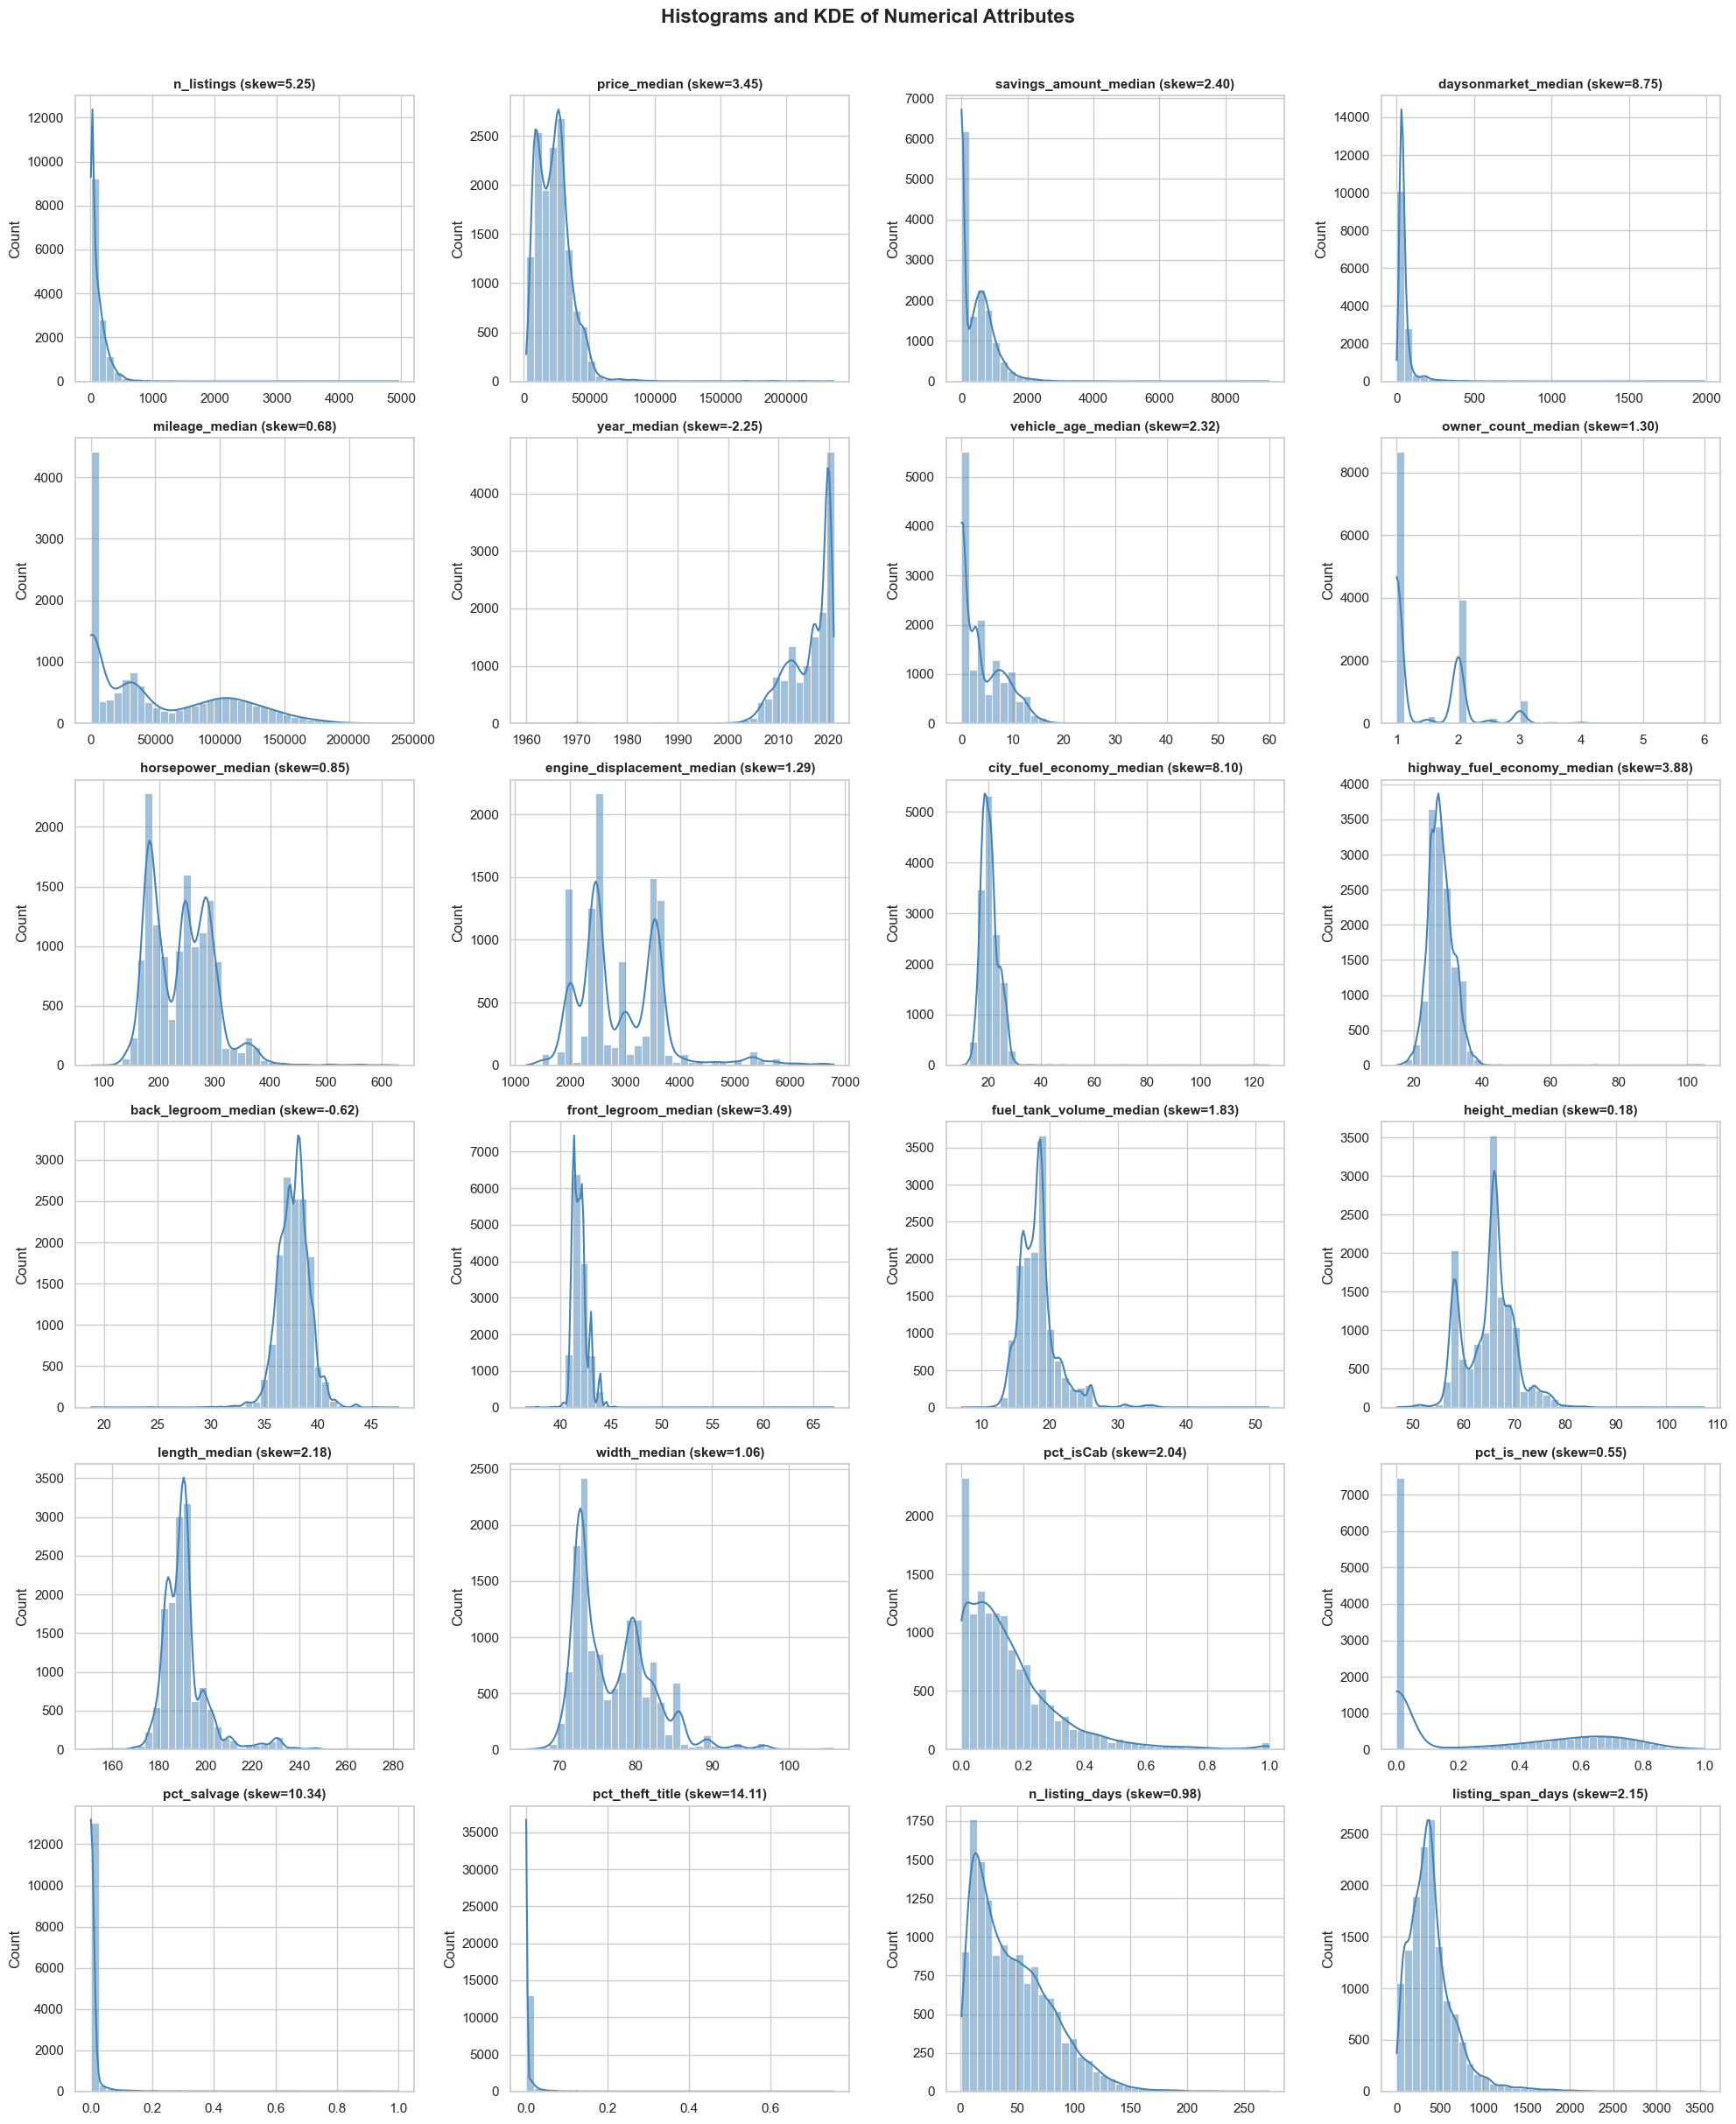

In [5]:
fig, axes = plt.subplots(6, 4, figsize=(20, 24))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(df[col].dropna(), kde=True, bins=40, ax=axes[i], color="steelblue")
    axes[i].set_title(f"{col} (skew={df[col].skew():.2f})", fontsize=11, fontweight="bold")
    axes[i].set_xlabel("")

# Hide unused subplots
for j in range(len(num_cols), len(axes)):
    axes[j].axis("off")

plt.suptitle("Histograms and KDE of Numerical Attributes", fontsize=16, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()


#### Key Insights from Histograms and KDE Plots (1.2.2)

Visual inspection of the 24 numerical histograms and Kernel Density Estimation (KDE) curves reveals **five distinct distributional patterns** that reflect the underlying automotive domain:

1. **Bimodal and Multimodal Distributions (Market Segmentation & Vehicle Engineering Standards):**
   * **New vs. Used Inventory Separation (`mileage_median`, `pct_is_new`, `year_median`, `vehicle_age_median`):**
     * `mileage_median` and `pct_is_new` are clearly **bimodal**: a sharp spike near $0\text{ miles}$ (franchise dealers selling brand-new vehicles, corresponding to `vehicle_age_median == 0` and `year_median == 2020`) is separated by a trough from a broad bell-shaped curve spanning $30,000\text{--}120,000\text{ miles}$ (independent used-car dealers).
     * Notably, `year_median` and `vehicle_age_median` exhibit a prominent secondary peak at **model year $2017$ ($\text{age} = 3\text{ years}$, $1,567$ sellers)** alongside the primary peak at $2020$ ($\text{age} = 0$, $4,173$ sellers). In the automotive market, the 3-year mark corresponds to the standard maturity of **3-year vehicle leases**, creating a large influx of off-lease used vehicles entering dealer inventories.
   * **Powertrain & Body-Style Clusters (`engine_displacement_median`, `height_median`):**
     * `engine_displacement_median` is **multimodal**, with two dominant clusters: one around **$2,000\text{--}2,500\text{ cc}$** (standard 4-cylinder engines typical of sedans and compact crossovers) and another around **$3,500\text{--}3,600\text{ cc}$** (standard V6 engines typical of full-size SUVs and pickup trucks).
     * `height_median` shows a secondary shoulder near **$58\text{ inches}$** (low-profile sedans) and a main peak around **$66\text{--}68\text{ inches}$** (SUVs and crossovers, which dominate the dataset).

2. **Heavily Right-Skewed (Long-Tail) Distributions:**
   * Scale and pricing attributes—**`n_listings`** ($\text{skew} = 5.25$), **`price_median`** ($\text{skew} = 3.45$), **`savings_amount_median`** ($\text{skew} = 2.40$), **`daysonmarket_median`** ($\text{skew} = 8.75$), and **`listing_span_days`** ($\text{skew} = 2.15$)—have the bulk of their observations concentrated on the left (small-to-medium dealerships, mainstream cars priced at $\$15,000\text{--}\$30,000$, and turnover times of $25\text{--}50\text{ days}$), followed by extremely long right tails.
   * `savings_amount_median` also features a distinct spike at $0$ ($36.84\%$ of sellers advertise zero discount), followed by an exponential decay.
   * These long right tails visually justify applying **log-transformation (`np.log1p`)** in Section 1.4 to compress extreme values and achieve more symmetric distributions.

3. **Leptokurtic (Tightly Concentrated) Distributions Stretched by Domain Outliers:**
   * **`city_fuel_economy_median`** ($\text{skew} = 8.10$) and **`highway_fuel_economy_median`** ($\text{skew} = 3.88$) form a very narrow, tall peak around $18\text{--}22\text{ MPG}$ (city) and $25\text{--}30\text{ MPG}$ (highway) for conventional gasoline vehicles, while the horizontal axis is stretched up to $126\text{ MPG}$ by a handful of electric/hybrid dealerships (MPGe).
   * Similarly, **`front_legroom_median`** ($\text{skew} = 3.49$) and **`back_legroom_median`** ($\text{skew} = -0.62$) are tightly concentrated around $41\text{--}42\text{ inches}$ and $37\text{--}39\text{ inches}$ due to standardized ergonomic cabin design across manufacturers.

4. **Discrete, Step-Like Spikes:**
   * **`owner_count_median`** appears as discrete vertical spikes rather than a continuous curve: the dominant peak is at **$1.0$ previous owner** ($8,668$ sellers, $62.8\%$), followed by **$2.0$ owners** ($3,948$ sellers, $28.6\%$) and **$3.0$ owners** ($733$ sellers, $5.3\%$), with minor half-integer bars at $1.5$ and $2.5$. This indicates that most dealers focus on one- or two-owner vehicles.

5. **Zero-Inflated (Degenerate) Spikes at Zero:**
   * **`pct_salvage`** ($\text{skew} = 10.34$) and **`pct_theft_title`** ($\text{skew} = 14.11$) appear almost entirely as a single vertical spike at $0.0$, visually confirming that $>85\%\text{--}91\%$ of sellers have zero salvage or theft-title vehicles in their inventory, while **`pct_isCab`** ($\text{skew} = 2.04$) peaks near $0.0\text{--}0.15$ and rapidly tapers off.


### 1.2.3. Distribution of Categorical Variables (Pie Charts & Bar Charts)
Visualize the proportions of categorical variables and the target class `seller_rating_class`.


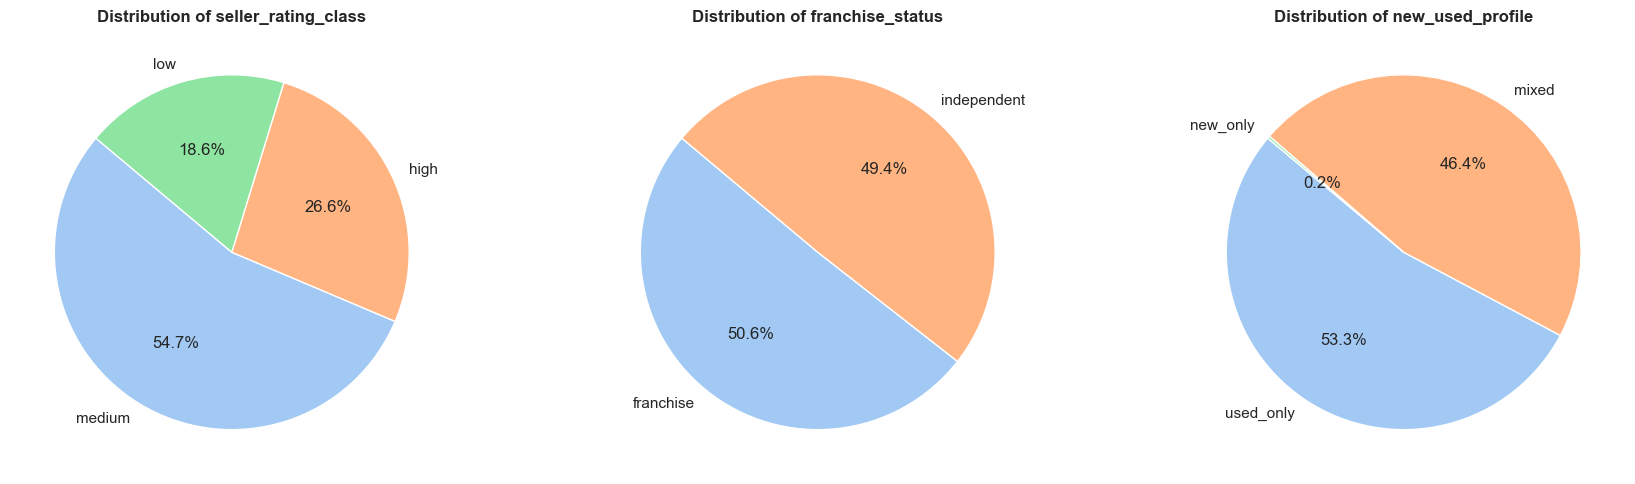

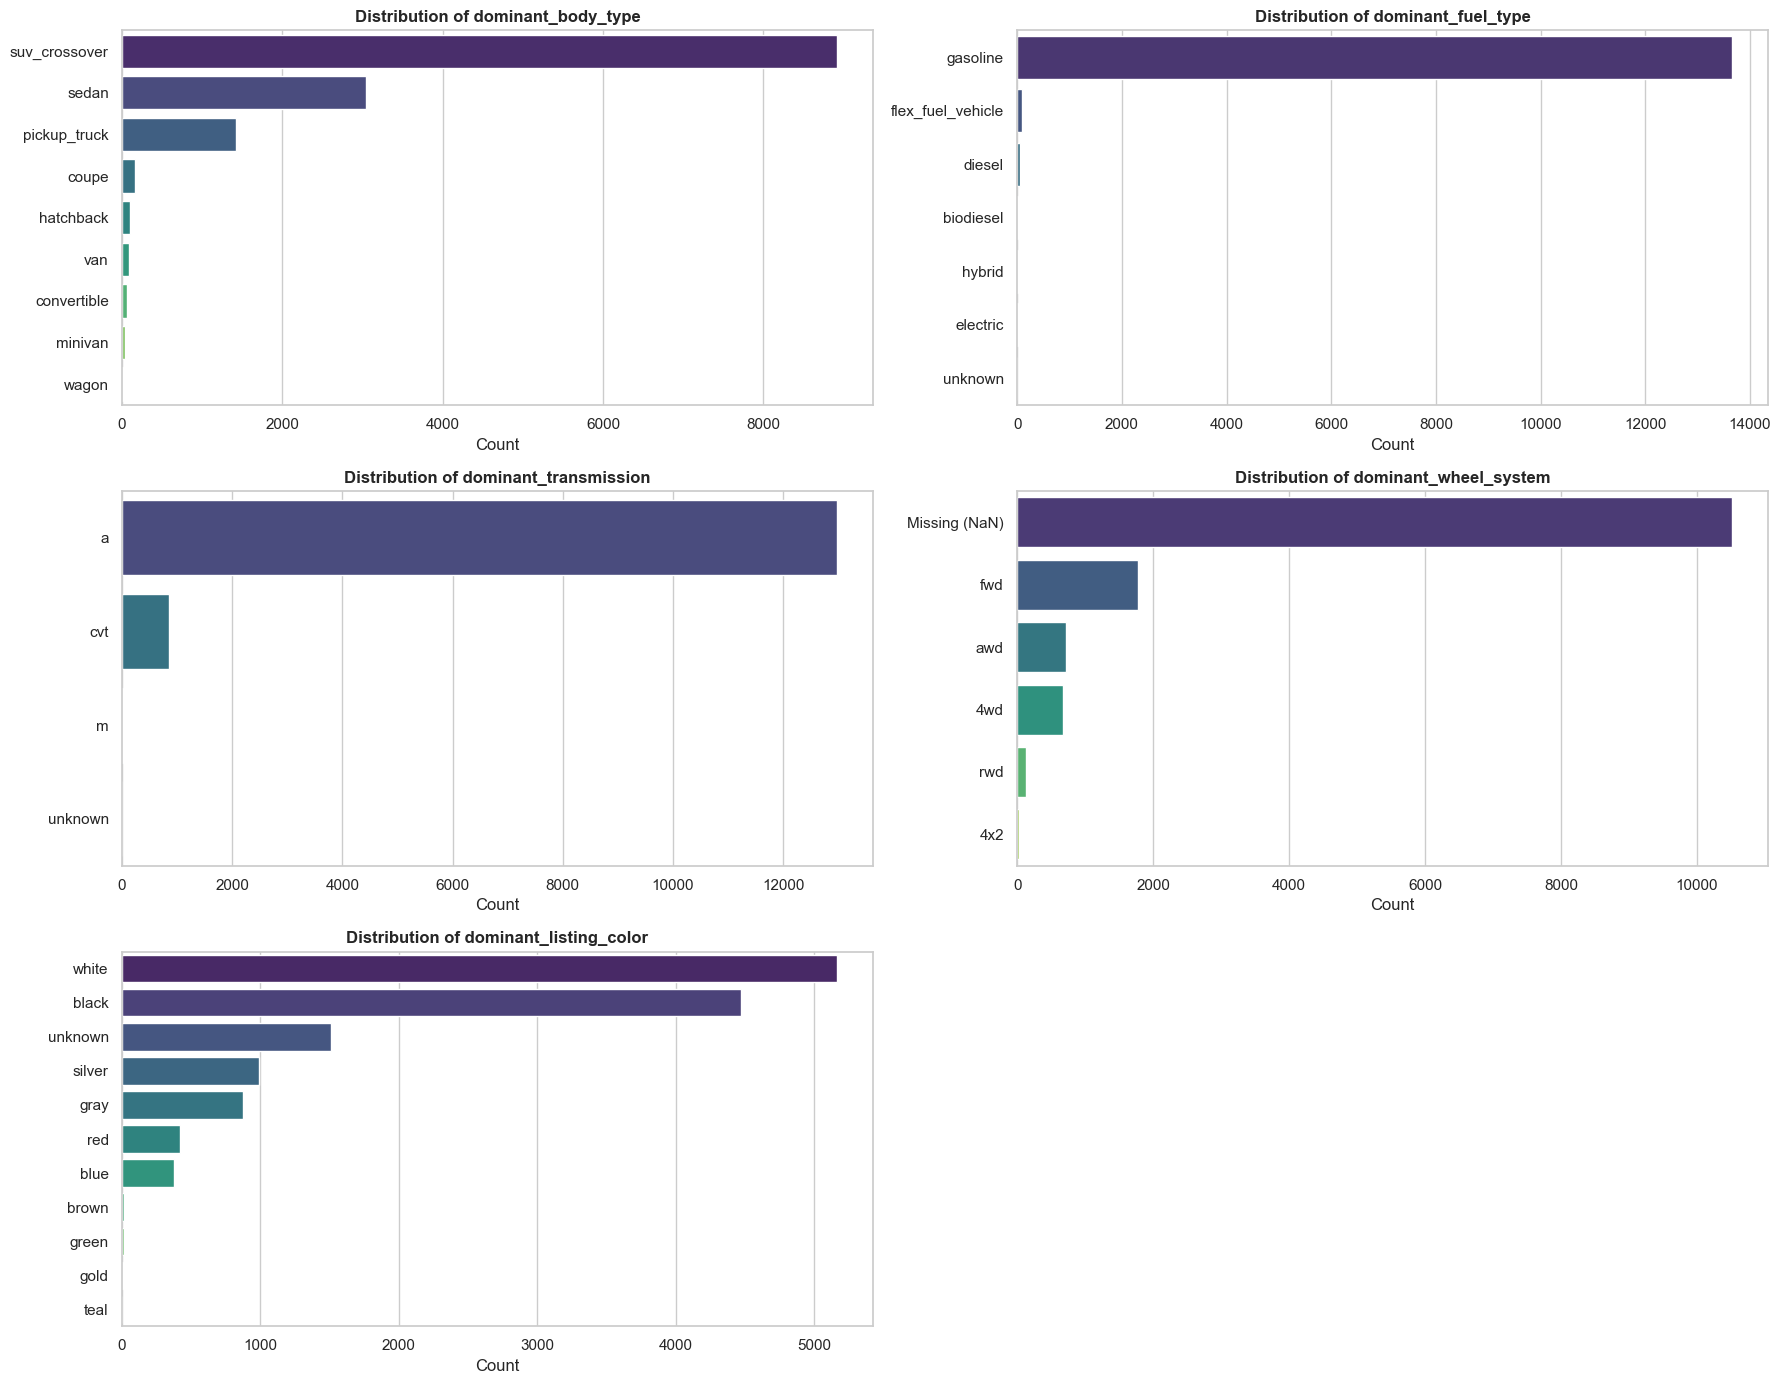

In [6]:
# Pie charts for low-cardinality categorical variables (franchise_status, new_used_profile, seller_rating_class)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

low_card_cols = ["seller_rating_class", "franchise_status", "new_used_profile"]
for i, col in enumerate(low_card_cols):
    counts = df[col].value_counts()
    axes[i].pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=140, colors=sns.color_palette("pastel"))
    axes[i].set_title(f"Distribution of {col}", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

# Bar charts for remaining categorical variables
high_card_cols = ["dominant_body_type", "dominant_fuel_type", "dominant_transmission", "dominant_wheel_system", "dominant_listing_color"]
fig, axes = plt.subplots(3, 2, figsize=(18, 14))
axes = axes.flatten()

for i, col in enumerate(high_card_cols):
    df_plot = df.fillna({"dominant_wheel_system": "Missing (NaN)"})
    order = df_plot[col].value_counts().index
    sns.countplot(data=df_plot, y=col, hue=col, order=order, ax=axes[i], palette="viridis", legend=False)
    axes[i].set_title(f"Distribution of {col}", fontsize=12, fontweight="bold")
    axes[i].set_xlabel("Count")
    axes[i].set_ylabel("")

axes[-1].axis("off")
plt.tight_layout()
plt.show()


#### Key Insights from Pie Charts and Bar Charts (1.2.3)

1. **Target Variable Distribution (`seller_rating_class` — Moderate Class Imbalance):**
   * The target variable is unevenly distributed across its three ordinal classes: **`medium`** dominates with **$54.7\%$** ($7,577$ sellers), followed by **`high`** at **$26.6\%$** ($3,687$ sellers), and **`low`** as the minority class at **$18.6\%$** ($2,579$ sellers).
   * *Methodological implication:* Because `medium` is nearly three times as frequent as `low`, downstream Classification models (Section 3) must use **stratified train-test splitting** and be evaluated via **Macro-F1, Per-Class Precision/Recall, and ROC-AUC** rather than overall Accuracy alone.

2. **Business Model & Inventory Profile (`franchise_status` & `new_used_profile`):**
   * **`franchise_status`** exhibits a nearly perfect 50/50 binary split between **`franchise`** ($50.6\%$, $6,999$ sellers) and **`independent`** ($49.4\%$, $6,844$ sellers), providing balanced representation of both dealership types.
   * **`new_used_profile`** is split almost entirely between **`used_only`** ($53.3\%$, $7,384$ sellers) and **`mixed`** ($46.4\%$, $6,428$ sellers), whereas **`new_only`** accounts for just **$0.2\%$** ($31$ sellers). This reveals that even authorized franchise dealers almost always maintain a mixed inventory by accepting used trade-ins and selling Certified Pre-Owned (CPO) vehicles alongside brand-new cars.

3. **Extreme Category Concentration in Vehicle Specifications (`dominant_body_type`, `dominant_fuel_type`, `dominant_transmission`):**
   * **`dominant_body_type`:** The top three body styles—**`suv_crossover`** ($64.4\%$, $8,920$ sellers), **`sedan`** ($22.0\%$, $3,044$ sellers), and **`pickup_truck`** ($10.3\%$, $1,424$ sellers)—collectively account for **$96.7\%$** of all sellers, while the remaining six body types (`coupe`, `hatchback`, `van`, `convertible`, `minivan`, `wagon`) represent only $3.3\%$ combined.
   * **`dominant_fuel_type`:** **`gasoline`** overwhelmingly dominates at **$98.7\%$** ($13,658$ sellers), leaving all alternative fuel types (`flex_fuel_vehicle`, `diesel`, `biodiesel`, `hybrid`, `electric`) with just $1.3\%$ combined. Due to this near-zero variance, `dominant_fuel_type` provides very limited discriminative power.
   * **`dominant_transmission`:** Automatic transmissions (**`a`**, **$93.7\%$**, $12,976$ sellers) and **`cvt`** (**$6.1\%$**, $847$ sellers) account for $99.8\%$ of the dataset, while manual (**`m`**) is negligible ($0.1\%$, $14$ sellers).
   * *Methodological implication:* Rare categories ($<1\%$ frequency) in `dominant_body_type` and `dominant_listing_color` should be grouped into an `"Other"` category prior to One-Hot Encoding or Association Rule Mining to prevent high-dimensional sparsity.

4. **Exterior Color Preferences (`dominant_listing_color`) & Missingness in `dominant_wheel_system`:**
   * Neutral colors dominate dealer inventories: **`white`** ($37.3\%$, $5,167$ sellers) and **`black`** ($32.3\%$, $4,475$ sellers) together represent nearly **$70\%$** of all sellers, followed by **`unknown`** ($10.9\%$, $1,510$ sellers), **`silver`** ($7.2\%$), and **`gray`** ($6.3\%$). Non-neutral colors (`red`, `blue`, `brown`, `green`, `gold`, `teal`) account for only $6.0\%$ combined.
   * In **`dominant_wheel_system`**, the bar chart visually highlights that **`Missing (NaN)`** ($76.0\%$, $10,518$ sellers) dwarfs all valid drivetrain categories (`fwd`: $12.9\%$, `awd`: $5.2\%$, `4wd`: $4.8\%$, `rwd`: $0.9\%$, `4x2`: $0.2\%$), directly justifying the removal of this attribute in Section 1.3.1.


---
## 1.3. Assessment of Data Quality
### 1.3.1. Missing Value Handling
Analyze both explicit `NaN` values and implicit `"unknown"` values, then apply tailored imputation / removal strategies:
* **`dominant_wheel_system` (76.0% missing):** Drop column due to excessive missingness.
* **`engine_displacement_median` (24.5% missing):** Impute using the **median grouped by `dominant_body_type` and `dominant_fuel_type`** (since engine size strongly depends on vehicle body type and fuel type).
* **`vehicle_age_median` (1 missing):** Calculate mathematically from `year_median` (`2020 - year_median`).
* **Remaining numerical columns with < 0.3% missing (`owner_count_median`, `pct_isCab`, `pct_salvage`, `pct_theft_title`, dimensions, fuel economy, horsepower, mileage):** Impute with group median (e.g., by `dominant_body_type` or `new_used_profile`).


,Variable,NaN Count,NaN (%),'unknown' Count,'unknown' (%),Total Missing,Total Missing (%)
18,dominant_wheel_system,10518,75.98,0,0.00,10518,75.98
4,engine_displacement_median,3393,24.51,0,0.00,3393,24.51
19,dominant_listing_color,0,0.00,1510,10.91,1510,10.91
2,owner_count_median,39,0.28,0,0.00,39,0.28
13,pct_isCab,27,0.20,0,0.00,27,0.20
15,pct_theft_title,27,0.20,0,0.00,27,0.20
14,pct_salvage,27,0.20,0,0.00,27,0.20
7,back_legroom_median,22,0.16,0,0.00,22,0.16
5,city_fuel_economy_median,16,0.12,0,0.00,16,0.12
6,highway_fuel_economy_median,16,0.12,0,0.00,16,0.12


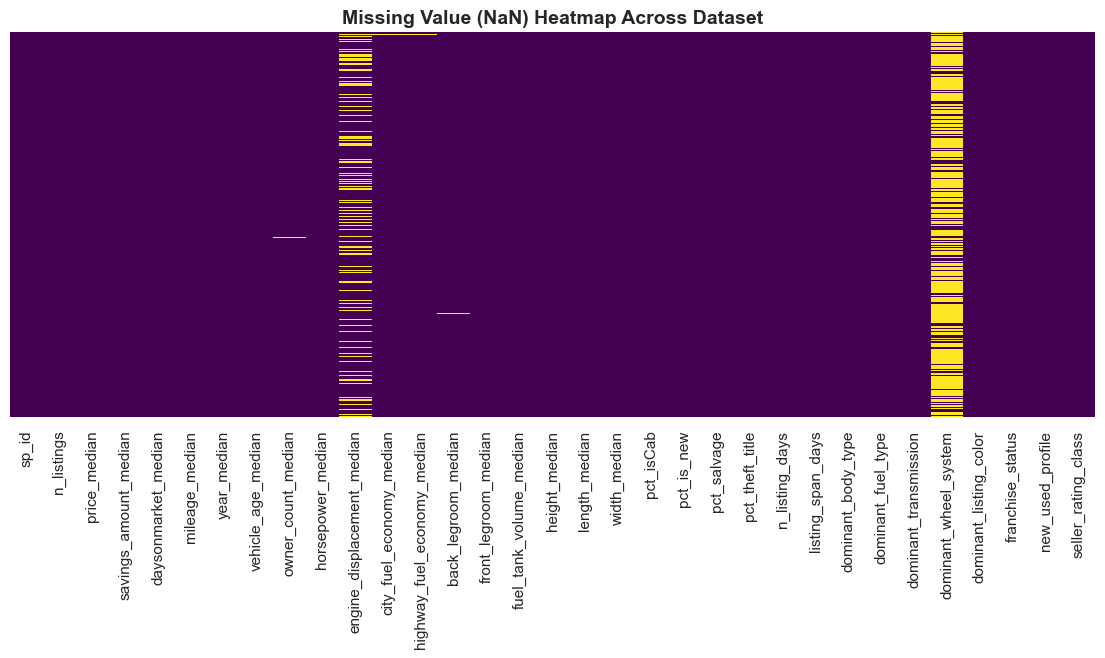

In [7]:
# Summary table of explicit NaN and implicit "unknown" values
missing_summary = []
for col in df.columns:
    nan_cnt = df[col].isnull().sum()
    unk_cnt = (df[col] == "unknown").sum() if df[col].dtype == "object" else 0
    total_miss = nan_cnt + unk_cnt
    if total_miss > 0:
        missing_summary.append({
            "Variable": col,
            "NaN Count": nan_cnt,
            "NaN (%)": round(nan_cnt / len(df) * 100, 2),
            "'unknown' Count": unk_cnt,
            "'unknown' (%)": round(unk_cnt / len(df) * 100, 2),
            "Total Missing": total_miss,
            "Total Missing (%)": round(total_miss / len(df) * 100, 2)
        })

missing_df = pd.DataFrame(missing_summary).sort_values(by="Total Missing", ascending=False)
display(missing_df)

# Visualize Missing Value Heatmap
plt.figure(figsize=(14, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing Value (NaN) Heatmap Across Dataset", fontsize=14, fontweight="bold")
plt.show()


In [8]:
# Apply Tailored Missing Value Handling on a working copy
df_clean = df.copy()

# 1. Drop dominant_wheel_system (76% missing)
df_clean.drop(columns=["dominant_wheel_system"], inplace=True)

# 2. Mathematical imputation for vehicle_age_median (listing year ~ 2020 - year_median)
mask_age = df_clean["vehicle_age_median"].isnull()
df_clean.loc[mask_age, "vehicle_age_median"] = 2020.0 - df_clean.loc[mask_age, "year_median"]

# 3. Group-based median imputation for engine_displacement_median by dominant_body_type
df_clean["engine_displacement_median"] = df_clean.groupby("dominant_body_type")["engine_displacement_median"].transform(
    lambda x: x.fillna(x.median())
)

# 4. Group-based median imputation for remaining numerical features with minor missing values (< 0.3%)
minor_num_missing = [c for c in num_cols if c in df_clean.columns and df_clean[c].isnull().sum() > 0]
for col in minor_num_missing:
    df_clean[col] = df_clean.groupby("dominant_body_type")[col].transform(lambda x: x.fillna(x.median()))
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# 5. Group-based mode imputation for negligible implicit 'unknown' in dominant_fuel_type (1) and dominant_transmission (6)
for col in ["dominant_fuel_type", "dominant_transmission"]:
    df_clean[col] = df_clean[col].replace("unknown", np.nan)
    df_clean[col] = df_clean.groupby("dominant_body_type")[col].transform(
        lambda x: x.fillna(x.mode()[0] if not x.mode().empty else df_clean[col].mode()[0])
    )

print("Remaining explicit NaN values after imputation:", df_clean.isnull().sum().sum())


Remaining explicit NaN values after imputation: 0


#### Key Insights from Missing Value Analysis & Justification of Imputation Strategies (1.3.1)

1. **Patterns Revealed by the Missing Value Table & Heatmap (Structured / Block Co-Missingness):**
   * Out of 33 attributes, **20 attributes** contain missing data (17 with explicit `NaN` values and 3 categorical attributes with implicit `'unknown'` strings), while **13 attributes** are $100\%$ complete.
   * Visual inspection of the Missing Value Heatmap and row-level indices reveals that missingness is **not purely random**, but occurs in **domain-specific blocks**:
     * **Title-History Block ($27$ sellers, $0.20\%$):** `pct_isCab`, `pct_salvage`, and `pct_theft_title` are missing on the **exact same 27 rows**, corresponding to sellers whose listings lacked vehicle history reports (e.g., Carfax/AutoCheck).
     * **EPA Fuel-Economy Block ($16$ sellers, $0.12\%$):** `city_fuel_economy_median` and `highway_fuel_economy_median` are missing on the **exact same 16 rows**, corresponding to dealers specializing in heavy-duty trucks or specialty vehicles exempt from standard EPA MPG ratings.
     * **Physical Spec-Sheet Block ($6\text{--}7$ sellers, $0.04\text{--}0.05\%$):** `height_median`, `length_median`, `width_median`, and `horsepower_median` are missing on the **exact same 6 rows** (which also overlap with the $7$ rows missing `front_legroom_median` and `fuel_tank_volume_median`), reflecting unrecorded factory specification sheets.

2. **Tailored Justification for Each Imputation / Elimination Decision:**
   * **`dominant_wheel_system` ($75.98\%$ missing, $10,518$ rows) $\rightarrow$ Feature Elimination (Drop Column):**
     * Because more than three-quarters of the records lack drivetrain information, any imputation strategy would synthesize $76\%$ of the column and severely distort downstream clustering and classification. Dropping the column is the only methodologically sound choice.
   * **`vehicle_age_median` ($1$ missing row, $0.01\%$) $\rightarrow$ Deterministic Mathematical Imputation:**
     * Seller `sp_id = 293033` has `year_median = 2020.0`. Using the exact domain formula $\text{vehicle\_age\_median} = 2020.0 - \text{year\_median}$, the missing value is deterministically recovered as $0.0$ years.
   * **`engine_displacement_median` ($24.51\%$ missing, $3,393$ rows) $\rightarrow$ Group-Based Median Imputation by `dominant_body_type`:**
     * At $24.51\%$ missingness, dropping the feature would discard valuable powertrain information, whereas global median imputation ($2,500\text{ cc}$) would ignore physical differences across vehicle segments. Imputing with the **median grouped by `dominant_body_type`** preserves domain semantics (assigning smaller 4-cylinder medians to sedans/hatchbacks and larger V6/V8 medians to pickup trucks and SUVs) while remaining robust to right-skewness and outliers.
   * **Remaining 14 Numerical Attributes with Minor Missingness ($<0.30\%$, $1\text{--}39$ rows) $\rightarrow$ Group-Based Median Imputation by `dominant_body_type`:**
     * Includes `owner_count_median` ($39$), `pct_isCab`/`pct_salvage`/`pct_theft_title` ($27$), `back_legroom_median` ($22$, including the $3$ erroneous zeros converted to `NaN` in Section 1.1.3), `city`/`highway_fuel_economy_median` ($16$), dimensions/horsepower ($6\text{--}7$), and `mileage_median` ($1$). Group-median imputation by `dominant_body_type` retains all $13,843$ sellers without distorting feature distributions.
   * **Implicit `'unknown'` in Categorical Attributes (`dominant_fuel_type`, `dominant_transmission`, `dominant_listing_color`):**
     * For `dominant_fuel_type` ($1$ row, $0.01\%$) and `dominant_transmission` ($6$ rows, $0.04\%$), `'unknown'` is replaced using the **mode segmented by `dominant_body_type`** (`'gasoline'` and `'a'`).
     * For `dominant_listing_color` ($1,510$ rows, $10.91\%$), because the top two colors (`'white'` at $37.3\%$ and `'black'` at $32.3\%$) have similar frequencies, mode imputation would artificially inflate `'white'` by nearly $11\%$. Thus, `'unknown'` is retained as a valid category representing sellers without a recorded dominant exterior color.


### 1.3.2. Outlier and Noise Detection
Visualize numerical distributions via Boxplots, inspect extreme values and semantic anomalies (e.g., `back_legroom_median == 0`), and decide which extreme points represent noise vs. valid domain outliers.


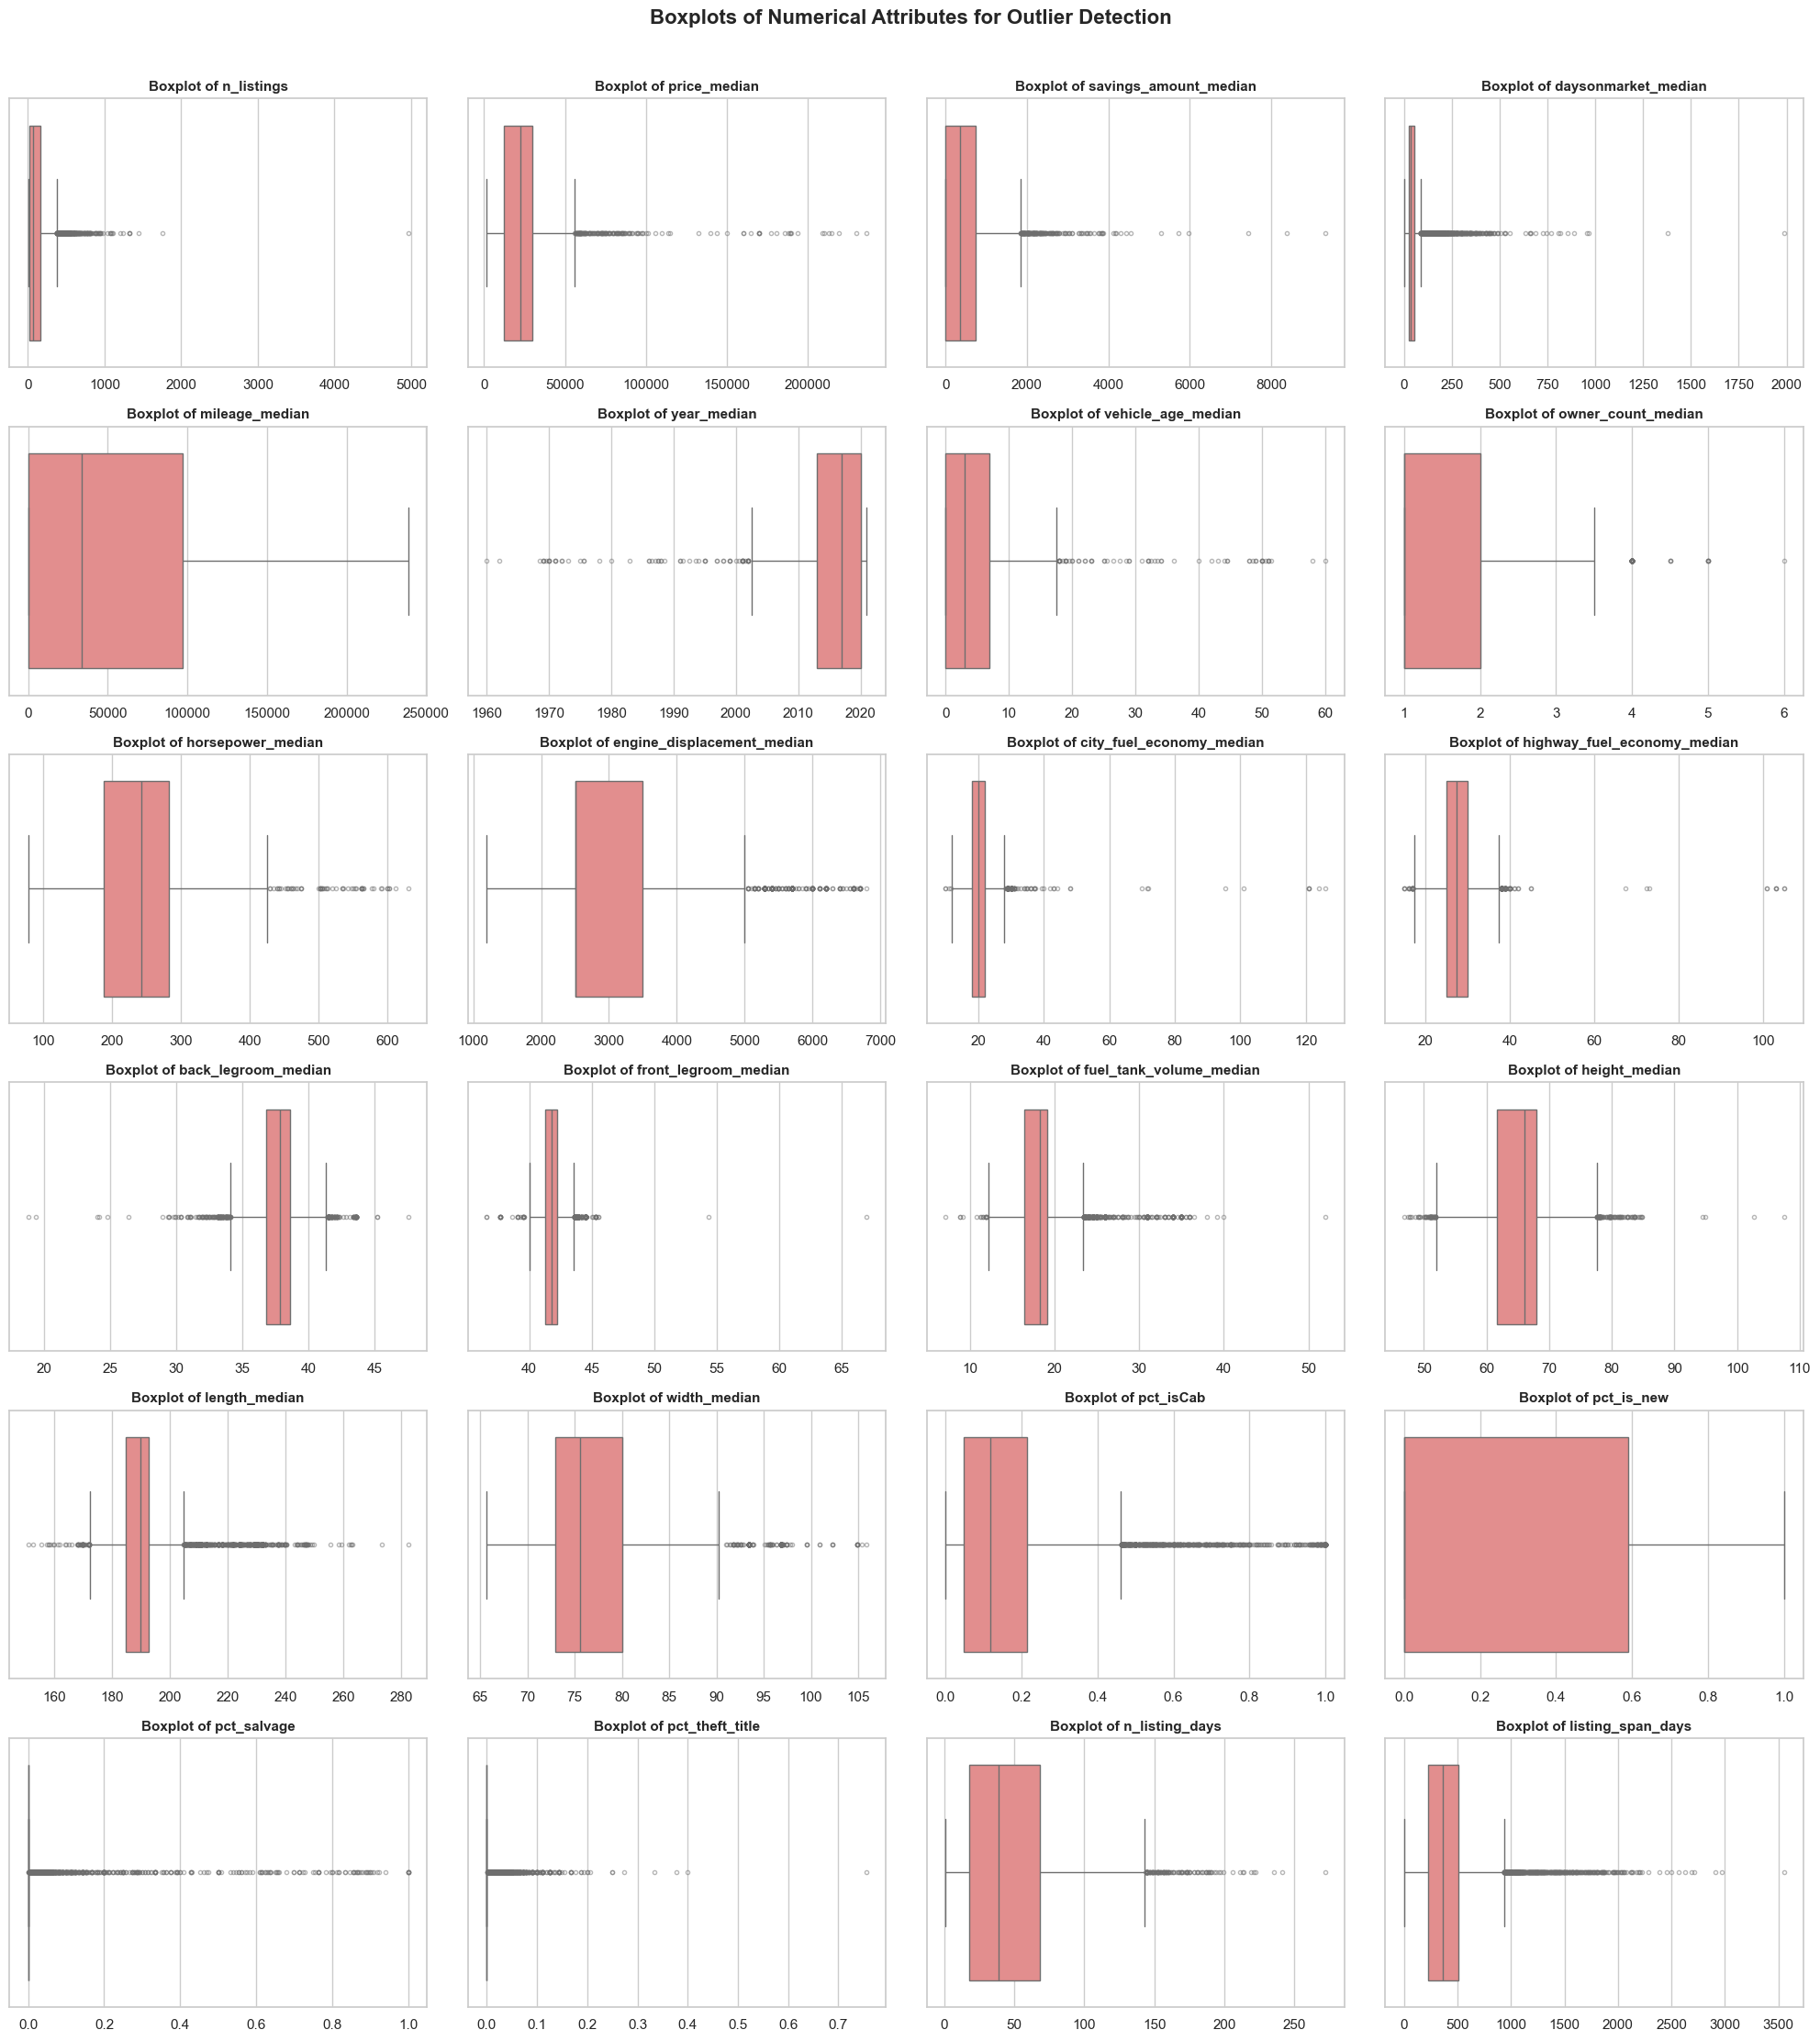

In [9]:
fig, axes = plt.subplots(6, 4, figsize=(20, 22))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    if col in df_clean.columns:
        sns.boxplot(x=df_clean[col], ax=axes[i], color="lightcoral", flierprops={"marker": "o", "markersize": 3, "alpha": 0.5})
        axes[i].set_title(f"Boxplot of {col}", fontsize=11, fontweight="bold")
        axes[i].set_xlabel("")

for j in range(len(num_cols), len(axes)):
    axes[j].axis("off")

plt.suptitle("Boxplots of Numerical Attributes for Outlier Detection", fontsize=16, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()


In [10]:
# Inspect potential anomalies and extreme outliers quantitatively (IQR rule & percentiles)
outlier_report = []
for col in num_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    n_outliers = ((df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)).sum()
    outlier_report.append({
        "Variable": col,
        "Min": df_clean[col].min(),
        "1%": df_clean[col].quantile(0.01),
        "Median": df_clean[col].median(),
        "99%": df_clean[col].quantile(0.99),
        "Max": df_clean[col].max(),
        "IQR Outliers": n_outliers,
        "IQR Outliers (%)": round(n_outliers / len(df_clean) * 100, 2)
    })

display(pd.DataFrame(outlier_report))

# Verify that the 3 erroneous back_legroom_median == 0 records were successfully handled
print("\nVerification - Rows remaining with back_legroom_median == 0:", (df_clean["back_legroom_median"] == 0).sum())


,Variable,Min,1%,Median,99%,Max,IQR Outliers,IQR Outliers (%)
0,n_listings,5.00,5.000,70.000000,572.480000,4959.000000,641,4.63
1,price_median,1699.00,4381.300,22385.000000,59920.570000,236438.000000,171,1.24
2,savings_amount_median,0.00,0.000,358.000000,2086.220000,9333.000000,218,1.57
3,daysonmarket_median,0.00,8.000,36.000000,280.000000,1987.000000,1110,8.02
4,mileage_median,0.00,0.000,33601.000000,174290.000000,238541.000000,0,0.00
5,year_median,1960.00,2004.500,2017.000000,2020.000000,2021.000000,65,0.47
6,vehicle_age_median,0.00,0.000,3.000000,15.000000,60.000000,62,0.45
7,owner_count_median,1.00,1.000,1.000000,3.000000,6.000000,51,0.37
8,horsepower_median,78.00,148.000,243.000000,385.000000,630.000000,62,0.45
9,engine_displacement_median,1200.00,1800.000,2500.000000,5700.000000,6800.000000,328,2.37



Rows with back_legroom_median == 0:


,sp_id,dominant_body_type,back_legroom_median,front_legroom_median,length_median


#### Key Insights from Boxplots & Outlier/Noise Detection (1.3.2)

1. **Zero-Inflated & Tightly Concentrated Distributions Create Artificial IQR Outliers:**
   - **Zero-Inflated Risk Ratios (`pct_theft_title`: $15.24\%$, `pct_salvage`: $8.97\%$):** Because over $75\%$ of sellers have $0.0$ salvage or theft-title vehicles, the Interquartile Range ($IQR = Q_3 - Q_1$) is near zero. Consequently, any seller with a non-zero proportion of salvage or theft vehicles is mathematically flagged as an IQR outlier, even though these represent a genuine segment of secondary/damaged-vehicle dealers rather than data noise.
   - **Tightly Standardized Ergonomic Specs (`front_legroom_median`: $3.92\%$, `fuel_tank_volume_median`: $5.82\%$, `length_median`: $6.65\%$):** Standard passenger cars and SUVs cluster tightly around the median (e.g., $98\%$ of sellers fall within $40.8\text{--}43.9\text{ in}$ for front legroom). Sellers specializing in heavy-duty commercial trucks, cargo vans, or compact two-seaters naturally fall outside the narrow $[Q_1 - 1.5\,IQR,\, Q_3 + 1.5\,IQR]$ fences.

2. **Distinguishing True Data Errors (Noise) from Valid Domain Outliers:**
   - **True Semantic Noise (`back_legroom_median == 0.0`):** Physical dimensions of $0.0\text{ in}$ for multi-seat SUVs/Sedans are impossible measurement artifacts. As identified in Section 1.1.3 and imputed in Section 1.3.1, all $3$ erroneous zero-legroom records have been eliminated (`Min` is now a realistic $18.80\text{ in}$).
   - **Extreme Stale-Inventory Outliers (`daysonmarket_median` up to $1,987\text{ days}$ [$8.02\%$ outliers], `listing_span_days` up to $3,553\text{ days}$ [$4.44\%$ outliers]):** While $99\%$ of sellers turn over inventory within $280\text{ days}$, a small fraction exhibits median days-on-market exceeding $1,000\text{ days}$ ($\approx 3\text{--}5.4\text{ years}$), likely reflecting unremoved "zombie" listings or ultra-niche collector inventories.
   - **Legitimate Niche Market Segments:**
     - *Electric & Hybrid Specialists:* `city_fuel_economy_median` up to $126\text{ MPG}$ and `highway_fuel_economy_median` up to $105\text{ MPG}$ ($<1\%$ outliers) represent valid EPA MPGe ratings for EV/PHEV dealerships.
     - *Luxury, Exotic & Classic Car Dealers:* `price_median` up to $\$236,438$ ($1.24\%$ outliers), `horsepower_median` up to $630\text{ HP}$ ($0.45\%$ outliers), and `year_median` down to $1960$ (`vehicle_age_median` up to $60\text{ years}$, $0.45\%$ outliers) represent legitimate high-end and vintage automobile dealers.
     - *Mega-Dealership Groups:* `n_listings` up to $4,959$ ($4.63\%$ outliers) reflects major regional dealership networks.

3. **Task-Specific Outlier Treatment Strategy for Downstream Modules:**
   - Instead of indiscriminately deleting all IQR outliers—which would wipe out over $25\%$ of the dataset and erase entire business segments (EV dealers, luxury dealers, salvage dealers, and high-volume franchises)—we adopt a **task-specific treatment strategy**:
     - **Distribution Compression (Section 1.4):** Apply `np.log1p` transformation to heavily right-skewed continuous features (`n_listings`, `price_median`, `savings_amount_median`, `daysonmarket_median`, `city_fuel_economy_median`, etc.) to pull extreme upper tails toward the center without losing records.
     - **Clustering & Distance-Based Models (Module 2 & KNN):** Combine log-transformation with robust scaling (`StandardScaler` / `RobustScaler`) and, during clustering preprocessing, filter or winsorize extreme univariate/multivariate anomalies (e.g., `daysonmarket_median > 1000` or extreme $99.5\text{th}$ percentile records) so they do not distort K-Means centroids or Euclidean distances.
     - **Tree-Based Models & Pattern Mining (Modules 3 & 4):** Retain valid domain outliers, as Decision Trees, Random Forests, and discretized association-rule bins naturally isolate extreme tails into dedicated leaf nodes or upper intervals without parametric distortion.

---
## 1.4. Variables Transformation
1. **Log-Transformation (`np.log1p`):** Many count, price, and duration attributes (`n_listings`, `price_median`, `savings_amount_median`, `daysonmarket_median`, `mileage_median`, `n_listing_days`) are heavily right-skewed. Applying `log1p` compresses extreme right tails and makes distributions more symmetric.
2. **Feature Scaling (`StandardScaler` / `MinMaxScaler`):** Because features have vastly different scales (e.g., `pct_*` in $[0, 1]$ vs. `price_median` up to $236,438$), scaling is essential for distance-based algorithms (K-Means, DBSCAN, Hierarchical Clustering, KNN).


In [11]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Compare skewness before and after log1p transformation on right-skewed variables
skewed_cols = [col for col in num_cols if df_clean[col].skew() > 1.5 and df_clean[col].min() >= 0]
print("Highly right-skewed columns (skew > 1.5):", skewed_cols)

skew_comparison = pd.DataFrame({
    "Original Skewness": df_clean[skewed_cols].skew().round(2),
    "Log1p Skewness": np.log1p(df_clean[skewed_cols]).skew().round(2)
})
display(skew_comparison)

# Create standardized (Z-score) and normalized (Min-Max) versions for downstream tasks
scaler_z = StandardScaler()
df_zscore = pd.DataFrame(scaler_z.fit_transform(df_clean[num_cols]), columns=num_cols, index=df_clean.index)

scaler_mm = MinMaxScaler()
df_minmax = pd.DataFrame(scaler_mm.fit_transform(df_clean[num_cols]), columns=num_cols, index=df_clean.index)

print("Z-Score Standardized Data (mean ~ 0, std ~ 1):")
display(df_zscore.describe().loc[["mean", "std", "min", "max"]].round(2))


Highly right-skewed columns (skew > 1.5): ['n_listings', 'price_median', 'savings_amount_median', 'daysonmarket_median', 'vehicle_age_median', 'engine_displacement_median', 'city_fuel_economy_median', 'highway_fuel_economy_median', 'front_legroom_median', 'fuel_tank_volume_median', 'length_median', 'pct_isCab', 'pct_salvage', 'pct_theft_title', 'listing_span_days']


,Original Skewness,Log1p Skewness
n_listings,5.25,-0.13
price_median,3.45,-0.45
savings_amount_median,2.40,-0.40
daysonmarket_median,8.75,0.47
vehicle_age_median,2.32,0.00
engine_displacement_median,1.55,0.64
city_fuel_economy_median,8.10,0.96
highway_fuel_economy_median,3.87,0.48
front_legroom_median,3.49,2.15
fuel_tank_volume_median,1.83,0.90


Z-Score Standardized Data (mean ~ 0, std ~ 1):


,n_listings,price_median,savings_amount_median,daysonmarket_median,mileage_median,year_median,vehicle_age_median,owner_count_median,horsepower_median,engine_displacement_median,city_fuel_economy_median,highway_fuel_economy_median,back_legroom_median,front_legroom_median,fuel_tank_volume_median,height_median,length_median,width_median,pct_isCab,pct_is_new,pct_salvage,pct_theft_title,n_listing_days,listing_span_days
mean,-0.00,0.00,0.00,-0.00,-0.00,-0.00,-0.00,0.00,-0.00,-0.00,0.00,-0.00,-0.00,0.00,0.00,-0.00,0.00,0.00,-0.00,0.00,-0.00,0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-0.83,-1.49,-0.86,-0.88,-0.99,-11.85,-0.88,-0.69,-2.86,-2.24,-2.69,-3.24,-12.92,-6.88,-3.83,-3.69,-3.91,-2.28,-0.99,-0.84,-0.15,-0.24,-1.34,-1.44
max,35.32,14.85,17.11,34.57,3.61,1.07,12.07,7.33,6.83,5.34,26.62,19.40,6.68,32.68,11.50,8.55,8.90,5.82,5.32,2.31,15.26,46.32,6.69,11.15


#### Key Insights from Variable Transformations & Scaling (1.4)

1. **Dramatic Skewness Reduction via Log-Transformation (`np.log1p`):**
   - **Continuous Business Scale, Price & Turnover Attributes:** Applying $\log(1 + x)$ effectively compresses extreme right tails and restores near-symmetry ($|\text{Skewness}| < 1.0$) for key operational variables: `n_listings` (skewness drops from $+5.25 \rightarrow -0.13$), `daysonmarket_median` ($+8.75 \rightarrow +0.47$), `price_median` ($+3.45 \rightarrow -0.45$), `savings_amount_median` ($+2.40 \rightarrow -0.40$), `vehicle_age_median` ($+2.32 \rightarrow 0.00$), `city_fuel_economy_median` ($+8.10 \rightarrow +0.96$), `highway_fuel_economy_median` ($+3.87 \rightarrow +0.48$), `engine_displacement_median` ($+1.55 \rightarrow +0.64$), and `fuel_tank_volume_median` ($+1.83 \rightarrow +0.90$).
   - **Why $\log(1 + x)$ instead of $\log(x)$?** Attributes like `savings_amount_median`, `daysonmarket_median`, `mileage_median`, and `vehicle_age_median` contain valid zero values ($x = 0.0$), where $\log(0)$ is undefined ($-\infty$) while $\log(1 + 0) = 0.0$.

2. **Limitations of Log-Transformation on Zero-Inflated Ratios & Bounded Physical Specs:**
   - For bounded proportions already in $[0, 1]$ with massive point masses at zero (`pct_theft_title`: $+14.12 \rightarrow +10.64$, `pct_salvage`: $+10.35 \rightarrow +9.33$, `pct_isCab`: $+2.04 \rightarrow +1.47$), `np.log1p` acts nearly linearly ($\ln(1+x) \approx x$ for small $x$) and cannot eliminate the structural zero-inflation. These features should remain on their original $[0, 1]$ scale (or be discretized into binary/categorical indicators for Pattern Mining).
   - Similarly, tightly concentrated physical dimensions (`front_legroom_median`, `length_median`) are already bounded in a narrow physical range and benefit more from standardization or outlier winsorization than logarithmic compression.

3. **Necessity of Feature Scaling (`StandardScaler` vs. `MinMaxScaler`) & Effect of Raw Tails:**
   - **Resolving Scale Disparity:** In the raw dataset, `mileage_median` ($[0,\, 238,541]$) and `price_median` ($[1,699,\, 236,438]$) are five orders of magnitude larger than ratio variables (`pct_*` $\in [0, 1]$). Without scaling, Euclidean/Manhattan distance computations in **K-Means, Hierarchical Clustering, DBSCAN, and KNN** would be almost entirely dictated by mileage and price.
   - **Impact of Uncompressed Outliers on Z-Scores:** As seen in the `df_zscore` summary table (`mean = 0.00, std = 1.00`), applying `StandardScaler` directly to *untransformed* skewed variables still yields extreme maximum Z-scores (e.g., `pct_theft_title` $\max = +46.32\,\sigma$, `n_listings` $\max = +35.32\,\sigma$, `daysonmarket_median` $\max = +34.57\,\sigma$). Therefore, for distance-based models in Module 2, **`np.log1p` must be applied to skewed continuous features *prior* to Z-score or Min-Max scaling**.

---
## 1.5. Pairwise Correlations and Variable Elimination
### 1.5.1. Pairwise Scatter Plot Matrix
Visualize pairwise relationships among representative numerical attributes to observe linear and non-linear trends.


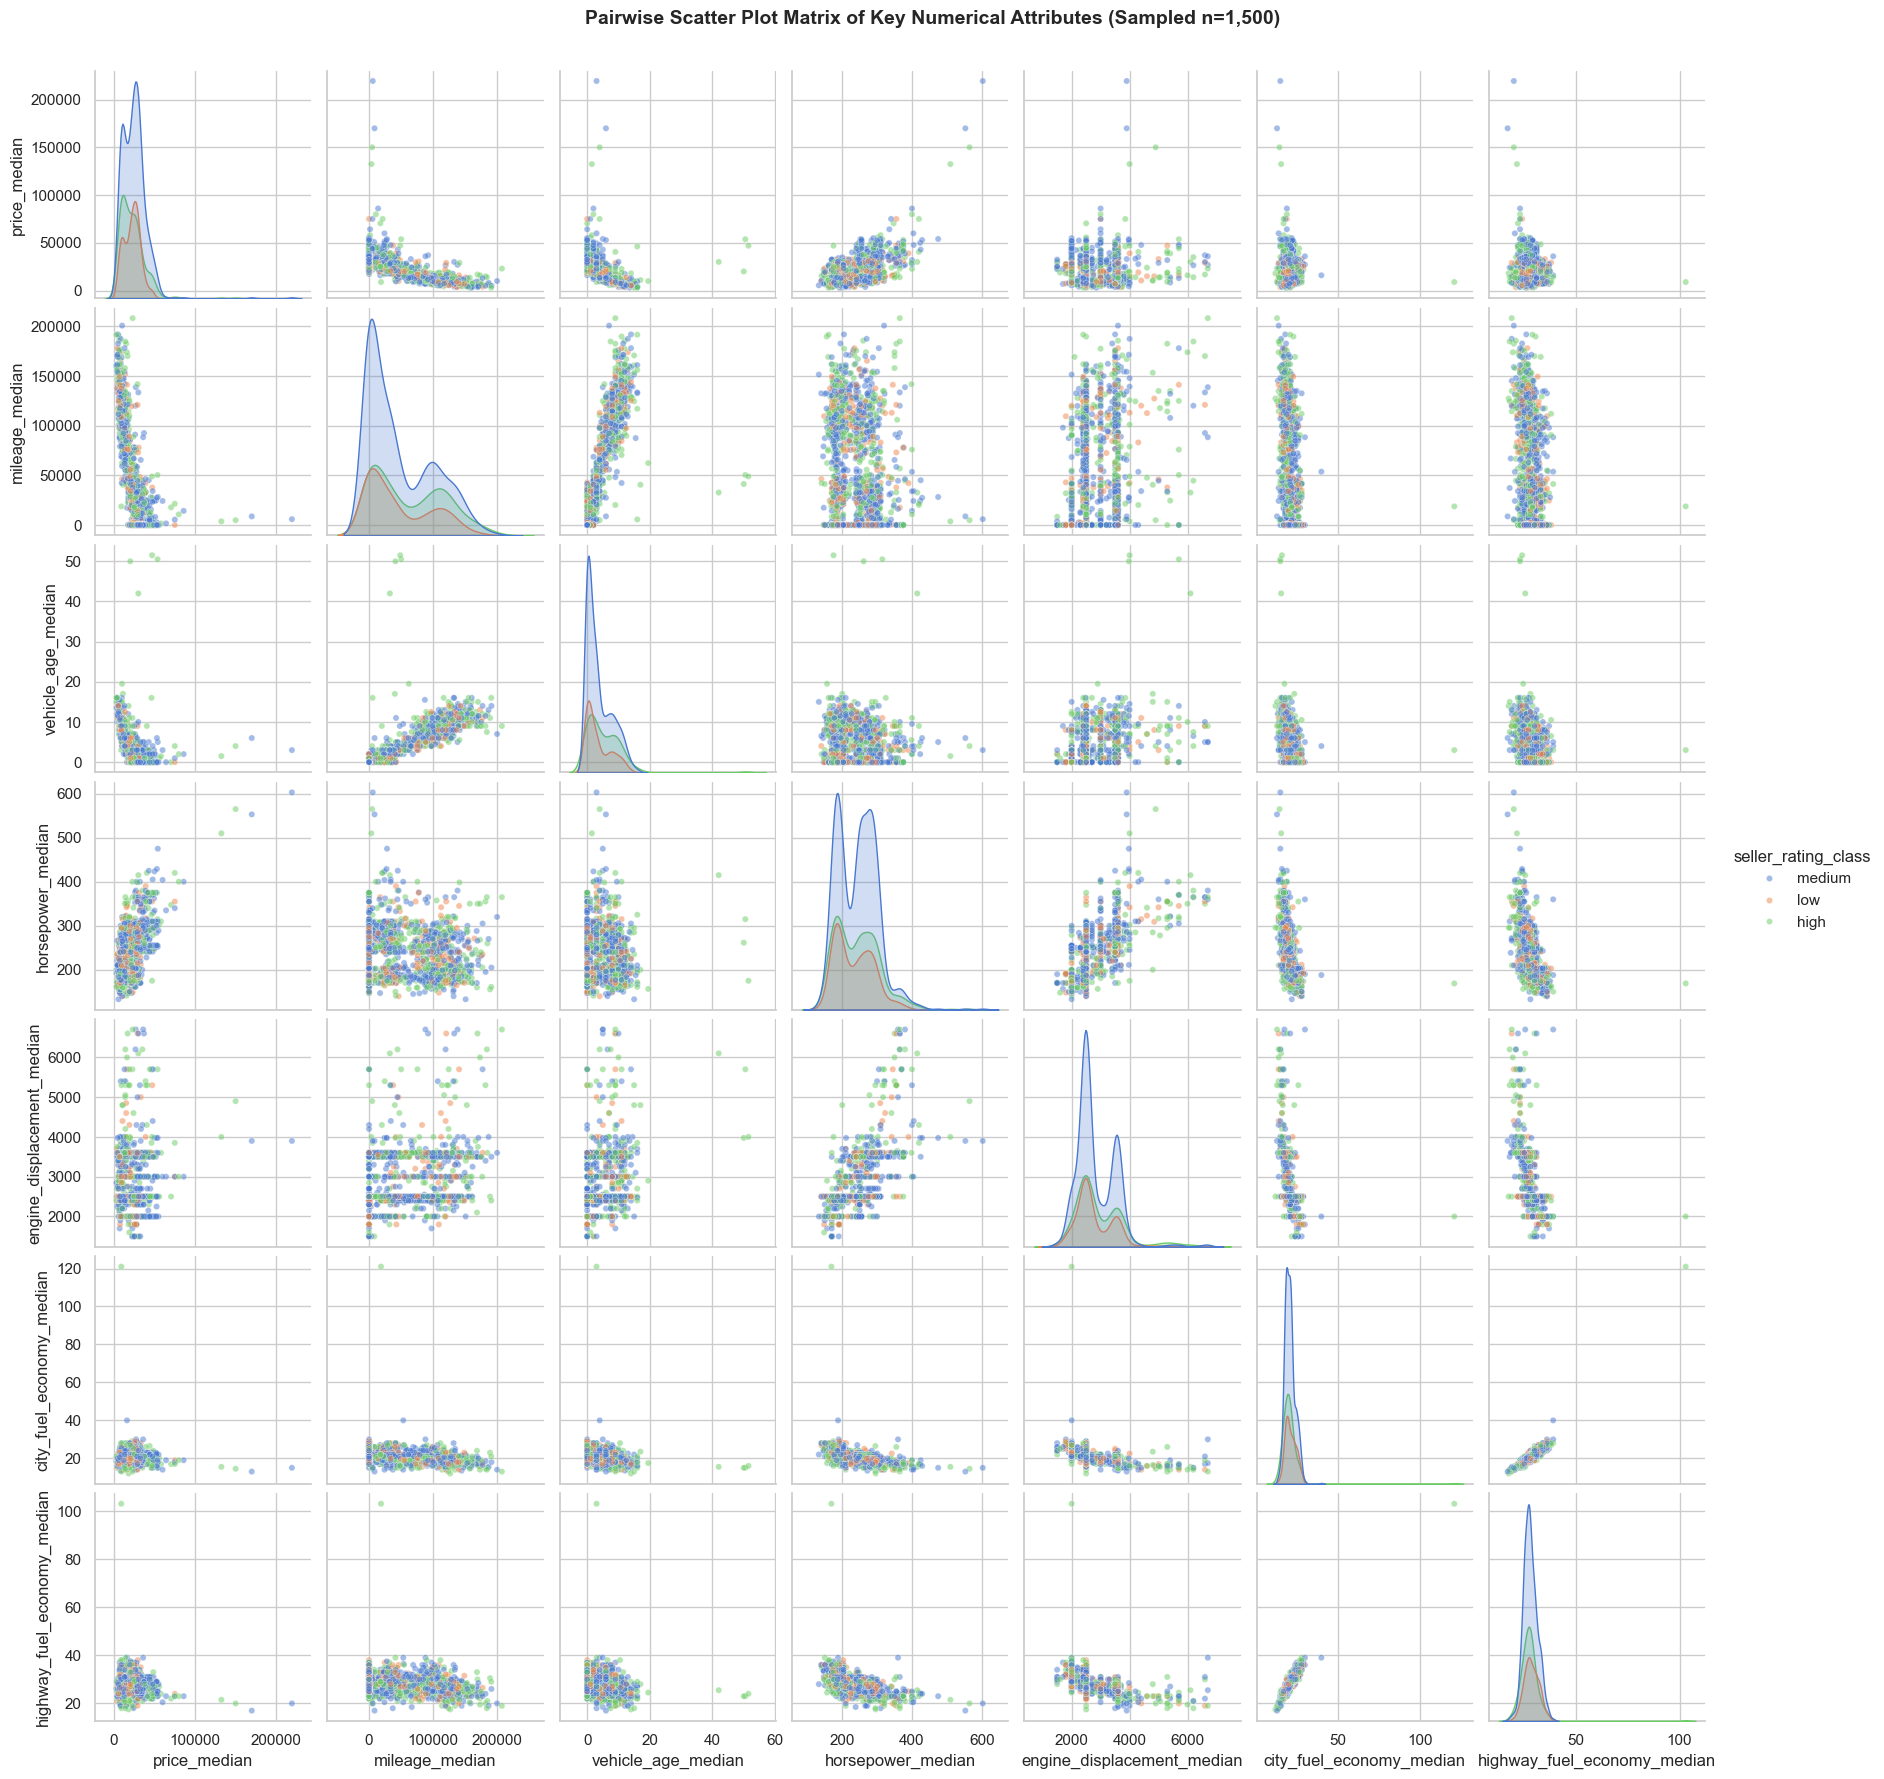

In [12]:
sample_pair_cols = [
    "price_median", "mileage_median", "vehicle_age_median",
    "horsepower_median", "engine_displacement_median",
    "city_fuel_economy_median", "highway_fuel_economy_median"
]

sns.pairplot(
    df_clean[sample_pair_cols + ["seller_rating_class"]].sample(n=1500, random_state=42),
    hue="seller_rating_class",
    diag_kind="kde",
    plot_kws={"alpha": 0.5, "s": 20}
)
plt.suptitle("Pairwise Scatter Plot Matrix of Key Numerical Attributes (Sampled n=1,500)", y=1.02, fontsize=14, fontweight="bold")
plt.show()


#### Key Insights from Pairwise Scatter Plot Matrix (1.5.1)

1. **Non-Linear Depreciation Curve (`price_median` vs. `mileage_median` & `vehicle_age_median`):**
   - The scatter plots clearly reveal an **exponential decay (L-shaped) relationship**: median vehicle prices drop steeply during the first $3\text{--}5\text{ years}$ (or first $50,000\text{ miles}$) and then flatten out asymptotically for older, high-mileage inventories. Because this relationship is monotonic but non-linear, **Spearman rank correlation ($r_s$)** is much more appropriate than linear Pearson correlation ($r_p$).

2. **Strong Linear Collinearity (`city_fuel_economy_median` vs. `highway_fuel_economy_median` & `mileage_median` vs. `vehicle_age_median`):**
   - `city_fuel_economy_median` and `highway_fuel_economy_median` form a tight, linear diagonal band across both conventional ICE vehicles ($15\text{--}40\text{ MPG}$) and the upper-right electric/hybrid cluster ($>60\text{ MPGe}$), confirming severe redundancy.
   - `mileage_median` and `vehicle_age_median` exhibit a strong positive fan-shaped trend: older inventories naturally accumulate higher mileage, though dispersion widens for vehicles over $10\text{ years}$ old.

3. **Powertrain Trade-Offs (`horsepower_median` vs. `engine_displacement_median` & Fuel Economy):**
   - `horsepower_median` increases positively with `engine_displacement_median` (forming distinct horizontal bands corresponding to standard $4$-cylinder [$\sim 2.0\text{--}2.5\text{L}$], $V6$ [$\sim 3.5\text{L}$], and $V8$ [$\sim 5.0\text{--}6.2\text{L}$] engines), while both correlate negatively with fuel economy.

4. **Target Class Overlap (`seller_rating_class` = Low, Medium, High):**
   - Looking at the diagonal KDE curves and scatter color-coding, the three `seller_rating_class` groups overlap substantially across physical vehicle specs, with a subtle shift showing **High-rated sellers** concentrating slightly more in newer, lower-mileage, and higher-priced vehicle segments. This indicates that predicting `seller_rating_class` in Module 3 is a non-trivial task requiring multivariate interactions across both dealer operational metrics (`n_listings`, `daysonmarket_median`, `franchise_status`) and inventory quality.

### 1.5.2. Spearman Correlation Matrix Heatmap & Redundant Feature Elimination
We compute the **Spearman rank correlation matrix** (more robust to outliers and non-linear monotonic relationships than Pearson) and identify highly correlated feature pairs ($|r_s| > 0.80$) to eliminate redundant attributes.


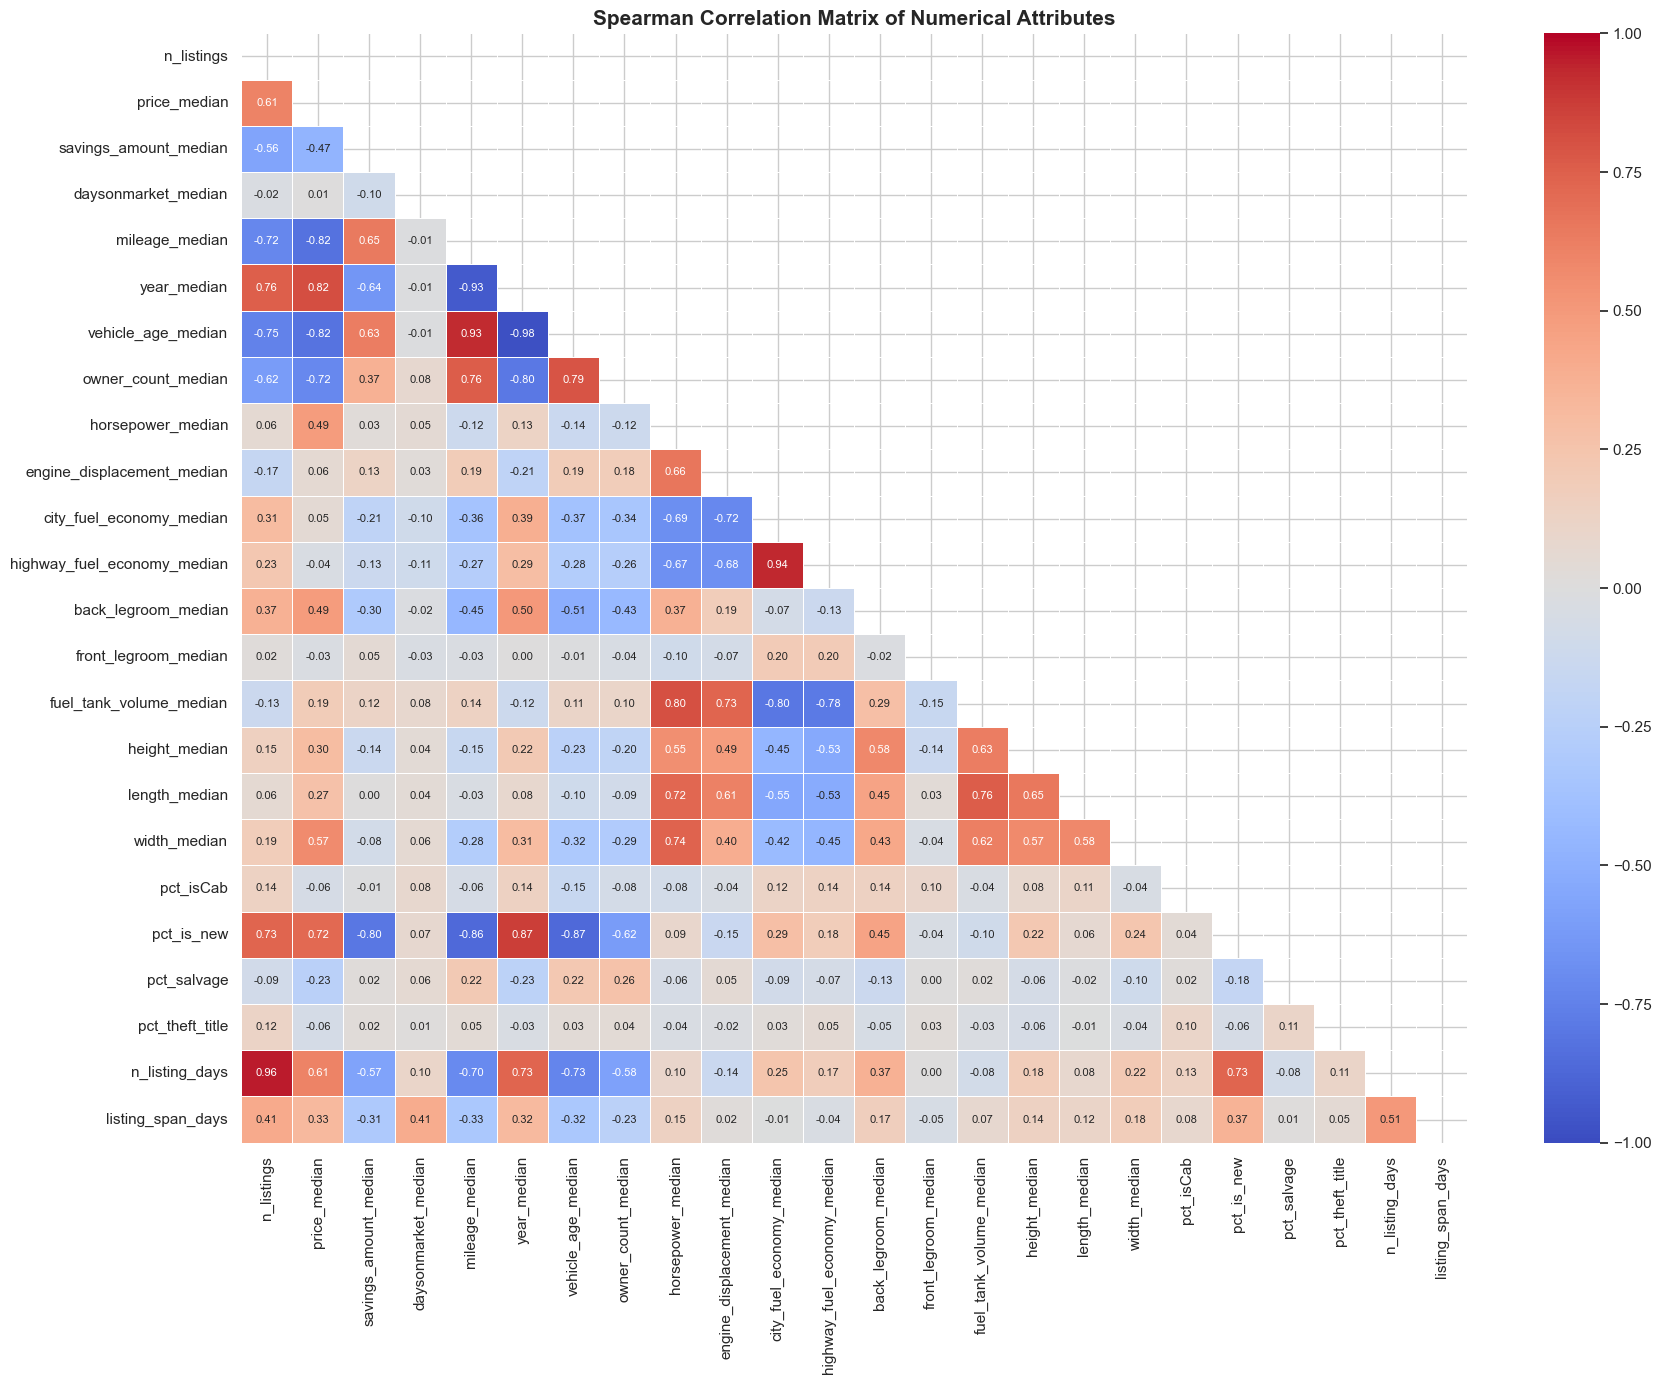

=== HIGHLY CORRELATED PAIRS (|r| >= 0.70) ===


,Feature 1,Feature 2,Spearman r
16,year_median,vehicle_age_median,-0.9837
4,n_listings,n_listing_days,0.9559
28,city_fuel_economy_median,highway_fuel_economy_median,0.9356
11,mileage_median,year_median,-0.9316
12,mileage_median,vehicle_age_median,0.9268
18,year_median,pct_is_new,0.8727
21,vehicle_age_median,pct_is_new,-0.8671
14,mileage_median,pct_is_new,-0.8614
5,price_median,mileage_median,-0.8226
6,price_median,year_median,0.8195


In [13]:
corr_spearman = df_clean[num_cols].corr(method="spearman")

plt.figure(figsize=(18, 14))
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))
sns.heatmap(
    corr_spearman,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    linewidths=0.5,
    annot_kws={"size": 8}
)
plt.title("Spearman Correlation Matrix of Numerical Attributes", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

# List all pairs with |Spearman correlation| >= 0.70
high_corr_pairs = []
for i in range(len(num_cols)):
    for j in range(i + 1, len(num_cols)):
        c1, c2 = num_cols[i], num_cols[j]
        val = corr_spearman.loc[c1, c2]
        if abs(val) >= 0.70:
            high_corr_pairs.append({"Feature 1": c1, "Feature 2": c2, "Spearman r": round(val, 4)})

high_corr_df = pd.DataFrame(high_corr_pairs).sort_values(by="Spearman r", key=abs, ascending=False)
print("=== HIGHLY CORRELATED PAIRS (|r| >= 0.70) ===")
display(high_corr_df)


In [14]:
# Eliminate redundant features and identifier before downstream modeling
cols_to_drop = [
    "sp_id",                        # Unique identifier (no predictive/clustering value)
    "year_median",                  # Perfectly redundant with vehicle_age_median (r ~ -0.99)
    "highway_fuel_economy_median",  # Highly collinear with city_fuel_economy_median
]

df_final = df_clean.drop(columns=[c for c in cols_to_drop if c in df_clean.columns])
print(f"Final Prepared Dataset Shape: {df_final.shape[0]:,} rows x {df_final.shape[1]} columns")
print("Remaining columns:", df_final.columns.tolist())


Final Prepared Dataset Shape: 13,843 rows x 29 columns
Remaining columns: ['n_listings', 'price_median', 'savings_amount_median', 'daysonmarket_median', 'mileage_median', 'vehicle_age_median', 'owner_count_median', 'horsepower_median', 'engine_displacement_median', 'city_fuel_economy_median', 'back_legroom_median', 'front_legroom_median', 'fuel_tank_volume_median', 'height_median', 'length_median', 'width_median', 'pct_isCab', 'pct_is_new', 'pct_salvage', 'pct_theft_title', 'n_listing_days', 'listing_span_days', 'dominant_body_type', 'dominant_fuel_type', 'dominant_transmission', 'dominant_listing_color', 'franchise_status', 'new_used_profile', 'seller_rating_class']


#### Key Insights from Spearman Correlation Matrix & Feature Elimination Justification (1.5.2)

1. **Near-Perfect Collinearity Pairs ($|r_s| > 0.93$) & Redundant Feature Elimination:**
   - **`year_median` $\leftrightarrow$ `vehicle_age_median` ($r_s = -0.9837$):** As proven in Section 1.3.1, `vehicle_age_median` is a direct deterministic transformation of `year_median` ($\text{vehicle\_age\_median} = 2020.0 - \text{year\_median}$). Keeping both introduces near-singular multicollinearity in regression and doubles the weight of vehicle age in distance-based clustering. **Decision:** Drop `year_median` and retain `vehicle_age_median` (which starts at $0.0$ and was cleanly log-transformed to $0.00$ skewness).
   - **`city_fuel_economy_median` $\leftrightarrow$ `highway_fuel_economy_median` ($r_s = +0.9356$):** Both variables capture the exact same underlying powertrain efficiency dimension. **Decision:** Drop `highway_fuel_economy_median` and retain `city_fuel_economy_median`.
   - **`n_listings` $\leftrightarrow$ `n_listing_days` ($r_s = +0.9559$):** Total listing volume and number of active posting days are strongly coupled. While both are retained in `df_final` for general exploratory flexibility (e.g., deriving listing intensity $\text{n\_listings} / \text{n\_listing\_days}$), `n_listing_days` should be excluded when selecting non-collinear clustering features in Module 2.

2. **The "Vehicle Condition & Lifecycle" Correlation Block ($0.81 \le |r_s| \le 0.93$):**
   - `mileage_median`, `vehicle_age_median`, `pct_is_new`, `price_median`, and `owner_count_median` form a tightly interconnected cluster:
     - Older inventory (`vehicle_age_median`) strongly correlates with higher `mileage_median` ($r_s = +0.9268$), more previous owners (`owner_count_median`, $r_s = +0.7926$), lower `pct_is_new` ($r_s = -0.8671$), and lower `price_median` ($r_s = -0.8154$).
     - Similarly, `mileage_median` correlates negatively with `price_median` ($r_s = -0.8226$) and `pct_is_new` ($r_s = -0.8614$).
   - **Modeling Implication:** Although `mileage_median` and `vehicle_age_median` are strongly correlated ($+0.9268$), both are retained in `df_final` because their divergence captures **usage intensity** (miles driven per year) and **price-to-condition value** for Regression/Classification (Module 3). For Clustering (Module 2), however, a compact subset of orthogonal representatives should be selected to avoid over-weighting the New-vs-Used dimension.

3. **The "Physical Size & Powertrain" Correlation Block ($0.71 \le |r_s| \le 0.80$):**
   - Vehicle dimensions and engine capacity move together across seller inventories: `fuel_tank_volume_median` correlates positively with `horsepower_median` ($r_s = +0.8049$), `length_median` ($r_s = +0.7596$), and `engine_displacement_median` ($r_s = +0.7301$), and negatively with `city_fuel_economy_median` ($r_s = -0.7977$). This reflects the contrast between dealers specializing in large Pickup Trucks/SUVs versus compact Sedans/Hatchbacks.

4. **Final Prepared Dataset Summary (`df_final`: $13,843\text{ rows} \times 29\text{ columns}$):**
   - Out of the initial $33$ attributes, **$4$ columns were eliminated** with rigorous statistical and semantic justification:
     1. `dominant_wheel_system` (Dropped in Section 1.3.1 due to $75.98\%$ missingness).
     2. `sp_id` (Dropped in Section 1.5.2 as a non-informative unique seller identifier).
     3. `year_median` (Dropped in Section 1.5.2 due to $r_s = -0.9837$ redundancy with `vehicle_age_median`).
     4. `highway_fuel_economy_median` (Dropped in Section 1.5.2 due to $r_s = +0.9356$ collinearity with `city_fuel_economy_median`).
   - Note: For linear/distance-based models, the deterministic categorical duplicate `new_used_profile` (which is $100\%$ determined by `pct_is_new`, as proven in Section 1.1.3) and `n_listing_days` ($r_s = +0.9559$ with `n_listings`) can also be excluded depending on the specific algorithm.